# Recursive Chunking & RAG Laboratory

### *Watch recursive chunking happen, then use it in a complete Retrieval-Augmented Generation pipeline*

---

## 0. Project Overview

This notebook is a **laboratory**, not a demo. Its goal is to remove the black box from two ideas:

1. **Recursive text chunking**: how a long document is cut into retrieval-sized pieces using a hierarchy of separators.
2. **Retrieval-Augmented Generation (RAG)**: how those chunks are embedded, stored, searched and handed to an LLM.

The strongest part of the notebook is the combination of four things:

| Feature | What it lets you do |
|---|---|
| **Custom recursion trace** | Read every recursive call: input, separator, pieces, keep/recurse decision, merge steps |
| **Visual recursion tree** | See depth, parent/child relationships, separators and sizes, generated *from the trace* |
| **Chunk-size experiment** | Run the same algorithm at 5 chunk sizes with overlap derived from chunk size |
| **Actual retrieval evaluation** | Measure which chunk size really retrieves the right evidence (Recall@k, MRR) |

> **Design rule of this notebook:** every conclusion is computed from the data in the notebook. Nothing in the "results" or "conclusion" sections is hard-coded, so re-running with different settings stays honest.

## 1. Learning Objectives

After working through the notebook you should be able to:

- explain what *chunk size*, *chunk overlap* and a *separator* are, and why recursion needs several separators;
- point at **any final chunk** and answer *"where did this chunk come from?"* (final chunk → merge → pieces → recursive call → separator decision → original characters);
- explain why a chunk size that "looks tidy" is not necessarily the one that retrieves best;
- compute cosine similarity by hand and verify that Qdrant agrees;
- trace a final answer back through the Groq prompt, retrieved context, similarity scores and the query embedding;
- state clearly what recursive character splitting does **not** understand.

### Pipeline roadmap

```text
Raw document → Analysis → Recursive chunking → Chunks → MiniLM embeddings → Qdrant
                                                                              ↑
User query → Query embedding → Similarity search ─────────────────────────────┘
                                      ↓
                              Top-k context → Groq LLM → Final answer
```

A drawn version of this diagram appears right after the imports.

## 2. Imports & Environment

### Installation

The next cell installs any **missing** package with `pip` (it does nothing if everything is already installed). Required packages:

| Package | Purpose |
|---|---|
| `numpy`, `pandas`, `matplotlib`, `scikit-learn` | maths, tables, plots, PCA |
| `sentence-transformers` | local MiniLM embedding model (`all-MiniLM-L6-v2`) |
| `qdrant-client` | local vector database (in-memory mode, no account needed) |
| `langchain-text-splitters` | **only** for the final comparison against a production splitter |
| `groq` | optional: Groq LLM generation (the notebook works without it) |

The first run downloads the MiniLM model (~90 MB) once. A `requirements.txt` is provided alongside the notebook.

In [1]:
# ── Installation cell (safe to re-run: installs only what is missing) ─────────
import sys, subprocess, importlib.util, os

REQUIRED = {                      # import name -> pip name
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "sklearn": "scikit-learn", "sentence_transformers": "sentence-transformers",
    "qdrant_client": "qdrant-client", "langchain_text_splitters": "langchain-text-splitters",
    "groq": "groq",
}
OPTIONAL = {"groq"}               # a failure to install these is not fatal

# RAGLAB_OFFLINE_TEST=1 is a developer switch used to test the notebook in a sandbox
# that cannot download models or call APIs. Leave it unset for normal use.
OFFLINE_TEST = os.getenv("RAGLAB_OFFLINE_TEST") == "1"
if OFFLINE_TEST:
    REQUIRED = {k: v for k, v in REQUIRED.items() if k not in ("sentence_transformers", "groq")}

missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    for pkg in missing:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg],
                           capture_output=True, text=True)
        if r.returncode != 0:
            msg = f"pip install {pkg} failed:\n{r.stderr[-600:]}"
            if pkg in OPTIONAL:
                print("[optional]", msg)
            else:
                raise RuntimeError(msg + "\nInstall it manually, then re-run this cell.")
    print("Done. If a package was just installed and an import below fails, restart the kernel once.")
else:
    print("All required packages are already installed.")

Installing missing packages: ['langchain-text-splitters', 'groq']


Done. If a package was just installed and an import below fails, restart the kernel once.


In [2]:
# ── Imports, configuration, reproducibility ──────────────────────────────────
import os, re, json, math, random, string, html, platform, warnings, zlib, textwrap
from dataclasses import dataclass, field
from typing import List, Optional, Dict, Any
from importlib import metadata

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, HTML, Markdown

# ---- Reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---- Experiment configuration (every later cell reads these constants) -----
EMBED_MODEL      = "sentence-transformers/all-MiniLM-L6-v2"
GROQ_MODEL       = os.getenv("GROQ_MODEL", "llama-3.3-70b-versatile")   # override via env var
SEPARATORS       = ["\n\n", "\n", ". ", " ", ""]       # coarse → fine
CHUNK_SIZES      = [150, 200, 250, 300, 400]           # sizes compared in the experiment
OVERLAP_RATIO    = 0.15                                # overlap = round(ratio × chunk_size)
DEMO_CHUNK_SIZE  = 150                                 # size for the guided walk-through (small enough to force deep recursion)
TOP_K            = 3                                   # chunks given to the LLM
EVAL_K           = 5                                   # deepest cut-off for Recall@k
QDRANT_PATH      = None                                # None = in-memory; or e.g. "./qdrant_local_db"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def pkg_version(name):
    try: return metadata.version(name)
    except metadata.PackageNotFoundError: return "not installed"

env_table = pd.DataFrame([
    ("Python", platform.python_version()),
    ("numpy", pkg_version("numpy")), ("pandas", pkg_version("pandas")),
    ("matplotlib", pkg_version("matplotlib")), ("scikit-learn", pkg_version("scikit-learn")),
    ("sentence-transformers", pkg_version("sentence-transformers")),
    ("qdrant-client (Qdrant)", pkg_version("qdrant-client")),
    ("langchain-text-splitters", pkg_version("langchain-text-splitters")),
    ("groq SDK", pkg_version("groq")),
    ("Embedding model", EMBED_MODEL), ("Embedding dimension", "384 (verified after the model loads)"),
    ("Groq model", GROQ_MODEL), ("Random seed", SEED),
], columns=["Component", "Version / setting"])
display(env_table.style.hide(axis="index"))

# ---- Secrets: the API key is read from the environment, never hard-coded ----
def get_groq_key():
    key = os.getenv("GROQ_API_KEY")
    if not key:                               # optional: Google Colab "Secrets" panel
        try:
            from google.colab import userdata
            key = userdata.get("GROQ_API_KEY")
        except Exception:
            key = None
    return key

if get_groq_key():
    print("GROQ_API_KEY: found (value hidden).  Generation steps will run.")
else:
    print("GROQ_API_KEY: NOT found.\n"
          "The notebook will still demonstrate chunking → embeddings → Qdrant → retrieval.\n"
          "Generation steps will be skipped gracefully.\n"
          "To enable them:  export GROQ_API_KEY='...'  (or add a Colab secret) and re-run.")

Component,Version / setting
Python,3.10.12
numpy,2.2.6
pandas,2.3.3
matplotlib,3.10.9
scikit-learn,1.7.2
sentence-transformers,5.6.0
qdrant-client (Qdrant),1.18.0
langchain-text-splitters,1.1.3
groq SDK,1.7.0
Embedding model,sentence-transformers/all-MiniLM-L6-v2


GROQ_API_KEY: NOT found.
The notebook will still demonstrate chunking → embeddings → Qdrant → retrieval.
Generation steps will be skipped gracefully.
To enable them:  export GROQ_API_KEY='...'  (or add a Colab secret) and re-run.


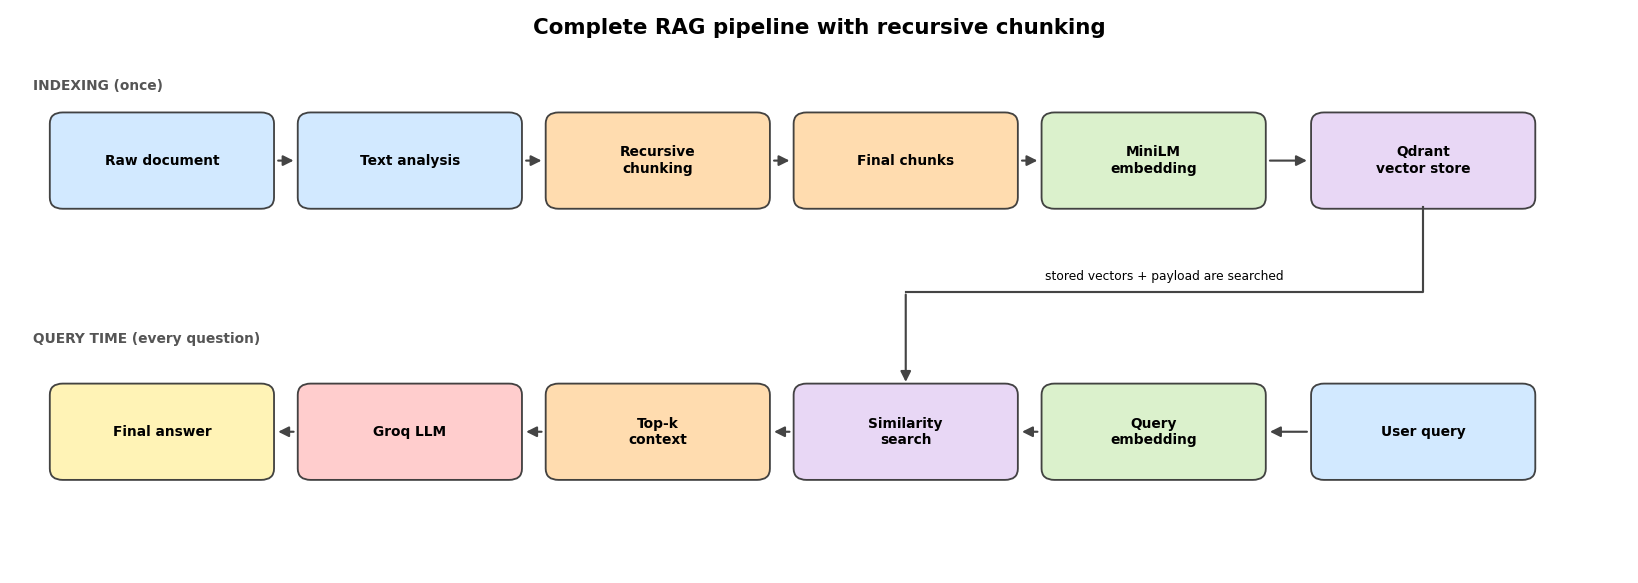

In [3]:
# ── A drawn pipeline diagram (matplotlib is more reliable than Mermaid in Jupyter) ──
def draw_pipeline(title="Complete RAG pipeline with recursive chunking", numbers=None):
    fig, ax = plt.subplots(figsize=(15, 5.4)); ax.set_xlim(0, 15); ax.set_ylim(0, 6); ax.axis("off")
    ax.text(7.5, 5.75, title, ha="center", fontsize=14, fontweight="bold")
    def box(x, y, label, color, w=2.0, h=0.95):
        ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                    fc=color, ec="#333333", lw=1.2, alpha=0.92))
        ax.text(x, y, label, ha="center", va="center", fontsize=9, color="black", fontweight="bold")
    def arrow(p, q, style="-|>"):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=14, lw=1.4, color="#444444"))
    numbers = numbers or {}
    top = [(("Raw document\n" + numbers.get("doc", "")).strip(), "#cfe8ff"), ("Text analysis", "#cfe8ff"),
           ("Recursive\nchunking", "#ffd9a8"), (("Final chunks\n" + numbers.get("chunks", "")).strip(), "#ffd9a8"),
           ("MiniLM\nembedding", "#d8f0c8"), ("Qdrant\nvector store", "#e6d4f5")]
    xs = [1.4, 3.7, 6.0, 8.3, 10.6, 13.1]
    for x, (lab, col) in zip(xs, top): box(x, 4.4, lab, col)
    for a, b in zip(xs[:-1], xs[1:]): arrow((a + 1.05, 4.4), (b - 1.05, 4.4))
    bottom = [("User query", "#cfe8ff"), ("Query\nembedding", "#d8f0c8"), ("Similarity\nsearch", "#e6d4f5"),
              ("Top-k\ncontext", "#ffd9a8"), ("Groq LLM", "#ffc9c9"), ("Final answer", "#fff3b0")]
    xs2 = [13.1, 10.6, 8.3, 6.0, 3.7, 1.4]
    for x, (lab, col) in zip(xs2, bottom): box(x, 1.5, lab, col)
    for a, b in zip(xs2[:-1], xs2[1:]): arrow((a - 1.05, 1.5), (b + 1.05, 1.5))
    # Qdrant is what the similarity search READS from: elbow connector Qdrant → Similarity search
    ax.plot([13.1, 13.1, 8.3], [3.9, 3.0, 3.0], color="#444444", lw=1.4)
    arrow((8.3, 3.0), (8.3, 2.0))
    ax.text(10.7, 3.12, "stored vectors + payload are searched", fontsize=8, ha="center")
    ax.text(0.2, 5.15, "INDEXING (once)", fontsize=9, color="#555555", fontweight="bold")
    ax.text(0.2, 2.45, "QUERY TIME (every question)", fontsize=9, color="#555555", fontweight="bold")
    plt.tight_layout(); plt.show()

draw_pipeline()

## 3. Source Document

We need a document that resembles **messy text extracted from a real web page**: a heading, prose, a menu, a table, checkboxes, opening hours and policies, all in *one* paragraph with only single line breaks, followed by a *second* paragraph of ordinary prose.

The content is original (a fictional "Maple Hall Café"). Two constraints are checked **programmatically** in the next cell, not by eye:

* exactly **2 paragraphs** (paragraphs are separated by a blank line, i.e. the two-character string `"\n\n"`; therefore paragraph 1 may contain single `"\n"` line breaks but never a blank line);
* exactly **1210 characters**.

In [4]:
# ── The source document ───────────────────────────────────────────────────────
PARAGRAPH_1 = """## Maple Hall Student Café & Services
Maple Hall Café serves students, staff and visitors on the ground floor of the Science Library, offering fresh meals, quiet seating and campus printing.
MENU
- Veggie Wrap ........ 5.50
- Chicken Rice Bowl .. 6.75
- Lentil Soup ........ 3.25
| Item          | Size   | Price |
|---------------|--------|-------|
| Filter Coffee | Medium | 2.20  |
| Green Tea     | Small  | 1.80  |
| Fruit Salad   | Bowl   | 3.40  |
Dietary options:
[x] Vegetarian  [x] Halal  [ ] Gluten-free  [ ] Vegan
Opening hours: Mon-Fri 08:00-18:00; Sat 09:00-14:00; closed Sunday.
Policy: Reusable cups receive a 0.30 discount. Cash is not accepted after 16:00.
Allergens: ask staff about nuts, dairy or sesame before ordering."""

PARAGRAPH_2 = ("Many universities now treat the campus café as an extension of the learning space. "
               "Students gather there between lectures to review notes, hold group meetings and decide what to study next. "
               "A reliable café reduces the time spent travelling off campus, and reusable cup schemes also lower waste. "
               "Staff often report that regular customers become informal ambassadors for the service. "
               "Good cafés therefore support both wellbeing and learning. Quiet corners help revision.")

DOCUMENT = PARAGRAPH_1 + "\n\n" + PARAGRAPH_2     # exactly what the chunker will receive
TARGET_LENGTH = 1210

# ---- Programmatic verification of the specification ----
import unicodedata
assert unicodedata.is_normalized("NFC", DOCUMENT), "Document must be NFC-normalised so that len() counts 'é' once"
assert len(DOCUMENT) == TARGET_LENGTH, f"Document has {len(DOCUMENT)} characters, expected {TARGET_LENGTH}"
assert len(DOCUMENT.split("\n\n")) == 2, "Document must contain exactly 2 paragraphs"
assert "\n\n" not in PARAGRAPH_1 and "\n\n" not in PARAGRAPH_2

structure_checks = {
    "Paragraph 1 has a sub-heading":      PARAGRAPH_1.startswith("## "),
    "Paragraph 1 has a menu":             "MENU" in PARAGRAPH_1 and "........" in PARAGRAPH_1,
    "Paragraph 1 has a table":            PARAGRAPH_1.count("|") >= 20 and "|---" in PARAGRAPH_1,
    "Paragraph 1 has checkboxes":         "[x]" in PARAGRAPH_1 and "[ ]" in PARAGRAPH_1,
    "Paragraph 1 has several line breaks": PARAGRAPH_1.count("\n") >= 10,
    "Paragraph 2 is plain prose":         not any(tok in PARAGRAPH_2 for tok in ["|", "[x]", "[ ]", "\n", "##", "...."]),
}
assert all(structure_checks.values()), structure_checks

print("═" * 60)
print(f"   DOCUMENT LENGTH = {len(DOCUMENT)} characters   (target {TARGET_LENGTH})  ✔ VERIFIED")
print("═" * 60)
print(f"   paragraph 1: {len(PARAGRAPH_1)} chars   |   paragraph 2: {len(PARAGRAPH_2)} chars   |   separator '\\n\\n': 2 chars")
for k, v in structure_checks.items(): print(("   ✔ " if v else "   ✘ ") + k)

════════════════════════════════════════════════════════════
   DOCUMENT LENGTH = 1210 characters   (target 1210)  ✔ VERIFIED
════════════════════════════════════════════════════════════
   paragraph 1: 740 chars   |   paragraph 2: 468 chars   |   separator '\n\n': 2 chars
   ✔ Paragraph 1 has a sub-heading
   ✔ Paragraph 1 has a menu
   ✔ Paragraph 1 has a table
   ✔ Paragraph 1 has checkboxes
   ✔ Paragraph 1 has several line breaks
   ✔ Paragraph 2 is plain prose


## 4. Document Statistics & Raw View

### 1. Raw Document

Below, the document is displayed in two ways. Both are **unmodified**: nothing is normalised, stripped, or re-wrapped before chunking.

* **View A** is the text exactly as the chunker receives it (monospaced, so tables and checkboxes keep their shape).
* **View B** makes invisible characters visible: `⏎` marks each newline and `¶` marks the blank line between the two paragraphs.

In [5]:
def show_raw_document(text):
    esc = html.escape(text)
    boundary = html.escape("\n\n")
    paras = text.split("\n\n")
    a = "<hr style='opacity:.3'>".join(
        f"<div style='background:rgba(100,150,255,.{9 if i==0 else 5}); padding:8px 12px; border-radius:6px; margin:4px 0'>"
        f"<b style='font-family:sans-serif;font-size:11px'>PARAGRAPH {i+1} · {len(p)} chars</b>"
        f"<pre style='margin:4px 0 0 0;font-size:12.5px;line-height:1.35'>{html.escape(p)}</pre></div>"
        for i, p in enumerate(paras))
    visible = html.escape(text).replace("\n\n", "<span style='color:#d33;font-weight:bold'> ⏎⏎¶ </span>\n").replace(
        "\n", "<span style='color:#d33'> ⏎</span>\n")
    b = f"<pre style='font-size:12px;line-height:1.4;background:rgba(127,127,127,.1);padding:8px 12px;border-radius:6px'>{visible}</pre>"
    display(HTML("<h4>View A: the document as the chunker receives it</h4>" + a +
                 "<h4>View B: whitespace made visible</h4>" + b))

show_raw_document(DOCUMENT)

In [6]:
# ── Document statistics ───────────────────────────────────────────────────────
def paragraph_spans(text, sep="\n\n"):
    spans, pos = [], 0
    for p in text.split(sep):
        spans.append((pos, pos + len(p))); pos += len(p) + len(sep)
    return spans

PARA_SPANS = paragraph_spans(DOCUMENT)        # [(0, 740), (742, 1210)]

def document_stats(text):
    return {
        "total characters": len(text),
        "paragraphs (split on blank line)": len(text.split("\n\n")),
        "lines (split on \\n)": len(text.split("\n")),
        "words (split on whitespace)": len(text.split()),
        "whitespace characters (all)": sum(c.isspace() for c in text),
        "   of which spaces": text.count(" "),
        "   of which newlines": text.count("\n"),
        "punctuation / symbol characters": sum(c in string.punctuation for c in text),
        "letters": sum(c.isalpha() for c in text),
        "digits": sum(c.isdigit() for c in text),
        "non-ASCII characters": sum(ord(c) > 127 for c in text),
    }

def display_document_stats(text):
    stats = document_stats(text)
    display(pd.DataFrame({"Metric": stats.keys(), "Value": stats.values()}).style.hide(axis="index"))
    rows = []
    for i, (s, e) in enumerate(paragraph_spans(text)):
        p = text[s:e]
        rows.append({"Paragraph": i + 1, "start index": s, "end index (excl.)": e, "characters": len(p),
                     "lines": len(p.split("\n")), "words": len(p.split()), "newlines": p.count("\n")})
    display(pd.DataFrame(rows).style.hide(axis="index"))
    print(f"Paragraph boundary '\\n\\n' occupies indexes {PARA_SPANS[0][1]}–{PARA_SPANS[1][0]-1}.")

display_document_stats(DOCUMENT)

Metric,Value
total characters,1210
paragraphs (split on blank line),2
lines (split on \n),18
words (split on whitespace),195
whitespace characters (all),221
of which spaces,204
of which newlines,17
punctuation / symbol characters,121
letters,827
digits,41


Paragraph,start index,end index (excl.),characters,lines,words,newlines
1,0,740,740,16,123,15
2,742,1210,468,1,72,0


Paragraph boundary '\n\n' occupies indexes 740–741.


### Character-level view

Chunkers work on **character indexes**, so being able to inspect any slice of the document is useful. `show_character_range(text, start, end)` prints a table; `show_char_ruler` prints a compact horizontal ruler for longer ranges. Invisible characters are drawn as `␠` (space) and `⏎` (newline).

In [7]:
SYMBOLS = {" ": "␠", "\n": "⏎", "\t": "⇥"}

def char_class(ch):
    if ch == "\n": return "newline"
    if ch == " ":  return "space"
    if ch.isalpha(): return "letter"
    if ch.isdigit(): return "digit"
    if ch in string.punctuation: return "punctuation"
    return "other"

def show_character_range(text, start=0, end=200):
    """Table view: INDEX | CHARACTER | repr | code point | class."""
    start, end = max(0, start), min(len(text), end)
    if start >= end: raise ValueError(f"empty range [{start}, {end}) for text of length {len(text)}")
    df = pd.DataFrame([{"INDEX": i, "CHARACTER": SYMBOLS.get(text[i], text[i]), "repr": repr(text[i]),
                        "UNICODE": f"U+{ord(text[i]):04X}", "CLASS": char_class(text[i])} for i in range(start, end)])
    display(df.style.hide(axis="index"))

def show_char_ruler(text, start=0, end=200, width=50):
    """Compact view: rows of `width` characters with an index ruler above each row."""
    start, end = max(0, start), min(len(text), end)
    for row in range(start, end, width):
        seg = text[row:min(row + width, end)]
        ruler = "".join(str((row + k) // 10 % 10) if (row + k) % 10 == 0 else "·" for k in range(len(seg)))
        print(f"{row:>5} {ruler}\n      {''.join(SYMBOLS.get(c, c) for c in seg)}\n")

print("First 12 characters, table view:"); show_character_range(DOCUMENT, 0, 12)
print("\nThe paragraph boundary (indexes 735–748), table view:"); show_character_range(DOCUMENT, 735, 748)
print("\nRuler view of the first 150 characters:\n"); show_char_ruler(DOCUMENT, 0, 150)

First 12 characters, table view:


INDEX,CHARACTER,repr,UNICODE,CLASS
0,#,'#',U+0023,punctuation
1,#,'#',U+0023,punctuation
2,␠,' ',U+0020,space
3,M,'M',U+004D,letter
4,a,'a',U+0061,letter
5,p,'p',U+0070,letter
6,l,'l',U+006C,letter
7,e,'e',U+0065,letter
8,␠,' ',U+0020,space
9,H,'H',U+0048,letter



The paragraph boundary (indexes 735–748), table view:


INDEX,CHARACTER,repr,UNICODE,CLASS
735,r,'r',U+0072,letter
736,i,'i',U+0069,letter
737,n,'n',U+006E,letter
738,g,'g',U+0067,letter
739,.,'.',U+002E,punctuation
740,⏎,'\n',U+000A,newline
741,⏎,'\n',U+000A,newline
742,M,'M',U+004D,letter
743,a,'a',U+0061,letter
744,n,'n',U+006E,letter



Ruler view of the first 150 characters:

    0 0·········1·········2·········3·········4·········
      ##␠Maple␠Hall␠Student␠Café␠&␠Services⏎Maple␠Hall␠C

   50 5·········6·········7·········8·········9·········
      afé␠serves␠students,␠staff␠and␠visitors␠on␠the␠gro

  100 0·········1·········2·········3·········4·········
      und␠floor␠of␠the␠Science␠Library,␠offering␠fresh␠m



## 5. Understanding Separators

### What is chunking, and why do we do it?

**Chunking** means cutting a document into smaller pieces ("chunks") before storing it for retrieval. We chunk because:

1. an embedding model compresses a *whole text* into **one** vector. A vector for a 50-page document is a blurry average, while a vector for a 3-sentence chunk is focused;
2. at question time we want to hand the LLM only the few passages that matter, not the whole document;
3. embedding models and LLMs have input-length limits and cost more with longer input.

### The key vocabulary

| Term | Meaning |
|---|---|
| **`chunk_size`** | The *maximum* length (here: in characters) we want a final chunk to have. It is a ceiling, not a target. |
| **`chunk_overlap`** | How many characters at the *end of one chunk* are repeated at the *start of the next*. It protects facts that sit on a boundary. |
| **separator** | A string at which text may be cut, such as a blank line, a newline, a sentence end or a space. |
| **recursive** | If a piece is still too big after cutting at one separator, *only that piece* is cut again with the next, finer separator. |

### Why several separators?

A single separator fails somewhere. Splitting only on spaces destroys structure (a table row becomes loose words). Splitting only on blank lines leaves huge pieces whenever a paragraph is long. **A hierarchy** lets us cut at the *most meaningful boundary that still produces small-enough pieces*, falling back to cruder boundaries only when forced.

In [8]:
separator_info = [
    ("\n\n", "paragraph break (blank line)", "Strongest structural boundary: authors put one idea per paragraph.",
     "Pieces that fit are kept and later merged with neighbours.", "Piece still > chunk_size → try '\\n'."),
    ("\n", "line break", "Lines are the next natural unit: table rows, menu items, checkbox lines, list bullets.",
     "Line pieces are kept intact (a table row stays a row).", "A line longer than chunk_size → try '. '."),
    (". ", "sentence end", "Inside long prose lines, sentences are the next meaningful unit.",
     "Sentences are kept whole and merged into chunks.", "A sentence longer than chunk_size → try ' '."),
    (" ", "word boundary", "Last 'semantic-ish' boundary: never cut inside a word if we can avoid it.",
     "Words are merged back into chunk-sized runs.", "Cannot fail unless a single word is huge → try ''."),
    ("", "single character", "Guaranteed fallback: always works, but may cut inside words.",
     "Characters are merged back into chunk-sized runs.", "No finer separator exists; text is emitted as-is."),
]
sep_df = pd.DataFrame(
    [(lvl, json.dumps(s), what, why, ok, fail, DOCUMENT.count(s) if s else len(DOCUMENT))
     for lvl, (s, what, why, ok, fail) in enumerate(separator_info)],
    columns=["Level", "Separator", "Represents", "Why it is attempted at this point", "If pieces fit", "If a piece does not fit", "Occurrences in our document"])
assert [s for s, *_ in separator_info] == SEPARATORS, "separator_info is out of sync with SEPARATORS"
display(sep_df.style.hide(axis="index"))

Level,Separator,Represents,Why it is attempted at this point,If pieces fit,If a piece does not fit,Occurrences in our document
0,"""\n\n""",paragraph break (blank line),Strongest structural boundary: authors put one idea per paragraph.,Pieces that fit are kept and later merged with neighbours.,Piece still > chunk_size → try '\n'.,1
1,"""\n""",line break,"Lines are the next natural unit: table rows, menu items, checkbox lines, list bullets.",Line pieces are kept intact (a table row stays a row).,A line longer than chunk_size → try '. '.,17
2,""". """,sentence end,"Inside long prose lines, sentences are the next meaningful unit.",Sentences are kept whole and merged into chunks.,A sentence longer than chunk_size → try ' '.,9
3,""" """,word boundary,Last 'semantic-ish' boundary: never cut inside a word if we can avoid it.,Words are merged back into chunk-sized runs.,Cannot fail unless a single word is huge → try ''.,204
4,"""""",single character,"Guaranteed fallback: always works, but may cut inside words.",Characters are merged back into chunk-sized runs.,No finer separator exists; text is emitted as-is.,1210


### Probing each separator on the whole document

What would each separator do **if used alone on the full 1210 characters**? This answers *"why isn't one separator enough?"* with numbers instead of opinion. The last column counts pieces longer than the demo chunk size.

In [9]:
def probe_separators(text, separators, chunk_size):
    rows = []
    for lvl, s in enumerate(separators):
        parts = [p for p in (text.split(s) if s else list(text)) if p != ""]
        lens = [len(p) for p in parts]
        rows.append({"Level": lvl, "Separator": json.dumps(s), "pieces": len(parts), "longest piece": max(lens),
                     "shortest piece": min(lens), "mean piece": round(sum(lens) / len(lens), 1),
                     f"pieces ≥ {chunk_size}": sum(l >= chunk_size for l in lens)})
    return pd.DataFrame(rows)

display(probe_separators(DOCUMENT, SEPARATORS, DEMO_CHUNK_SIZE).style.hide(axis="index"))

Level,Separator,pieces,longest piece,shortest piece,mean piece,pieces ≥ 150
0,"""\n\n""",2,740,468,604.000000,2
1,"""\n""",17,468,4,70.200000,2
2,""". """,10,364,26,119.200000,3
3,""" """,179,38,1,5.600000,0
4,"""""",1210,1,1,1.000000,0


## 6. What Recursive Chunking Means

Think of the algorithm as a **set of Russian dolls**. Start with the whole document and ask: *"Can I cut it at the coarsest boundary and get pieces that fit?"*

```text
DOCUMENT
   ↓
Try the first separator ("\n\n")
   ↓
Split into pieces
   ↓
For EACH piece:
      ├── piece fits (len < chunk_size)  → keep it (small pieces are collected for merging)
      └── piece too large                → take THAT piece alone, move to the NEXT separator,
                                            split it again, and repeat the same question
   ↓
Small kept pieces are MERGED back together (up to chunk_size)
   ↓
When a merge would overflow, the chunk is closed; the last few pieces (≤ chunk_overlap chars)
are carried over into the next chunk  →  OVERLAP
```

Three details are easy to miss and we will *see* all three in the trace:

1. **The recursion never restarts from the whole document.** It continues on the single oversized piece, with a *finer* separator.
2. **Splitting and merging are different steps.** Splitting makes pieces *smaller*; merging packs small pieces *back up* toward `chunk_size` so that chunks are not needlessly tiny.
3. **A separator that does not occur in the text is skipped** (there is nothing to cut), and the algorithm moves to the next one.

### The custom implementation vs. production libraries

Next we write the splitter ourselves, instrumented so that every decision is recorded. It follows the same conceptual algorithm as LangChain's `RecursiveCharacterTextSplitter`, including its implementation details (documented in the code comments), so that §26 can compare the two honestly. Beyond what the library does, ours also tracks the **absolute character offsets** of every piece and chunk, which makes provenance exact.

## 7. Custom Recursive Splitter

Read the code in this order: `_split` (the recursion), `_cut` (cutting at a separator), `_merge` (packing pieces into chunks with overlap). Every important line writes an **event** into `self.events` and fills a **call record** in `self.calls`. The explanatory displays in later sections are generated from these records.

**Implementation details worth knowing** (they mirror production splitters, and we flag where they matter):

* A piece "fits" if `len(piece) < chunk_size` (strictly smaller). A piece of *exactly* `chunk_size` characters is therefore treated as too large and gets recursed.
* Overlap is built from **whole pieces** retained at the end of a closed chunk. Actual overlap is therefore *at most* `chunk_overlap`, often less.
* Overlap only exists between chunks produced by the same *merge group*. A chunk that comes from a different recursive call does not overlap with its neighbour.
* By default separators are discarded when splitting and re-inserted when merging (`keep_separator=False`).

In [10]:
@dataclass
class Piece:
    pid: str          # unique id, e.g. "#2.P1" = piece 1 produced by recursive call #2
    text: str
    start: int        # absolute offset in the ORIGINAL document
    index: int
    @property
    def end(self): return self.start + len(self.text)

def q(s, limit=70):
    """Compact, unambiguous display of a string: quotes, escaped newlines, middle ellipsis."""
    if len(s) <= limit: return json.dumps(s, ensure_ascii=False)
    h = limit // 2
    return json.dumps(s[:h], ensure_ascii=False)[:-1] + " … " + json.dumps(s[-(limit - h):], ensure_ascii=False)[1:]

@dataclass
class Chunk:
    chunk_id: int
    text: str
    start: int
    end: int
    piece_ids: List[str]
    call: int                 # recursive call whose merge produced this chunk
    depth: int
    group: Optional[int]      # merge-group id (None if emitted as-is)
    oversize: bool
    overlap_prev: int = 0     # characters shared with the previous chunk (from spans)
    exact_slice: bool = True  # text == document[start:end] ?
    def __len__(self): return len(self.text)

@dataclass
class SplitResult:
    text: str
    chunk_size: int
    chunk_overlap: int
    separators: List[str]
    keep_separator: Any
    chunks: List[Chunk]
    calls: Dict[int, dict]
    events: List[dict]
    merge_steps: List[dict]
    warnings: List[str]

    def stats(self):
        lens = [len(c) for c in self.chunks]
        n = len(lens)
        return {
            "chunk_size": self.chunk_size, "overlap": self.chunk_overlap, "n_chunks": n,
            "avg_len": float(np.mean(lens)), "min_len": min(lens), "max_len": max(lens), "std_len": float(np.std(lens)),
            "pct_near_target": 100 * sum(0.8 * self.chunk_size <= l <= self.chunk_size for l in lens) / n,
            "n_calls": len(self.calls), "max_depth": max(c["depth"] for c in self.calls.values()),
            "n_transitions": sum(1 for e in self.events if e["type"] == "RECURSE"),
            "n_merge_ops": len(self.merge_steps),
            "overlap_chars": sum(c.overlap_prev for c in self.chunks),
            "n_oversize": sum(c.oversize for c in self.chunks),
            "granularity_pct_doc": 100 * float(np.mean(lens)) / len(self.text),
        }

In [11]:
class TracingRecursiveSplitter:
    """
    Educational recursive character splitter that records EVERYTHING it decides.

    Algorithm (same conceptual structure as LangChain's RecursiveCharacterTextSplitter):
      _split(text, separators):
         1. choose the first separator that actually occurs in the text (skip absent ones)
         2. cut the text at that separator → pieces
         3. walk through the pieces in order:
              - piece fits            → buffer it (to be merged with its small neighbours)
              - piece is too large    → (a) flush & merge the buffered small pieces,
                                        (b) recurse on THIS piece with the remaining (finer) separators
         4. flush any buffered pieces at the end
      _merge(pieces): pack pieces into chunks ≤ chunk_size, carrying ≤ chunk_overlap chars into the next chunk
    """
    def __init__(self, chunk_size, chunk_overlap, separators=None, keep_separator=False,
                 strip_whitespace=True, fit_strict=True):
        if isinstance(chunk_size, bool) or not isinstance(chunk_size, int) or chunk_size <= 0:
            raise ValueError(f"chunk_size must be a positive integer, got {chunk_size!r}")
        if isinstance(chunk_overlap, bool) or not isinstance(chunk_overlap, int) or chunk_overlap < 0:
            raise ValueError(f"chunk_overlap must be a non-negative integer, got {chunk_overlap!r}")
        if chunk_overlap >= chunk_size:
            raise ValueError(f"chunk_overlap ({chunk_overlap}) must be smaller than chunk_size ({chunk_size})")
        seps = list(SEPARATORS if separators is None else separators)
        if not seps: raise ValueError("separators must be a non-empty list")
        if not all(isinstance(s, str) for s in seps): raise TypeError("every separator must be a string")
        if keep_separator is True: keep_separator = "start"
        if keep_separator in (None, False): keep_separator = False
        if keep_separator not in (False, "start", "end"):
            raise ValueError("keep_separator must be False, 'start' or 'end'")
        self.chunk_size, self.chunk_overlap, self.separators = chunk_size, chunk_overlap, seps
        self.keep_separator, self.strip_whitespace, self.fit_strict = keep_separator, strip_whitespace, fit_strict

    # ------------------------------------------------------------------ public
    def split(self, text):
        if not isinstance(text, str): raise TypeError(f"text must be str, got {type(text).__name__}")
        if not text.strip(): raise ValueError("cannot chunk empty or whitespace-only text")
        self.text, self.calls, self.events, self.merge_steps, self.warnings = text, {}, [], [], []
        self._cid, self._gid = 0, 0
        if self.separators[-1] != "":
            self.warnings.append("The separator list has no '' fallback: pieces without any separator may stay oversized.")
        raw = self._split(Piece("ROOT", text, 0, 0), self.separators, parent=None, depth=0, origin="ROOT (entire document)")
        chunks = []
        for i, r in enumerate(raw):
            c = Chunk(i, r["text"], r["start"], r["end"], r["piece_ids"], r["call"], r["depth"], r["group"], r["oversize"])
            c.exact_slice = text[c.start:c.end] == c.text
            if i: c.overlap_prev = max(0, chunks[-1].end - c.start)
            chunks.append(c)
        # back-fill: which final chunk(s) does every piece end up in?
        for call in self.calls.values():
            for rec in call["pieces"]:
                rec["chunk_ids"] = [c.chunk_id for c in chunks if rec["pid"] in c.piece_ids]
        for call in self.calls.values():
            call["chunk_ids"] = [c.chunk_id for c in chunks if c.call == call["id"]]
        return SplitResult(text, self.chunk_size, self.chunk_overlap, self.separators, self.keep_separator,
                           chunks, self.calls, self.events, self.merge_steps, self.warnings)

    # ----------------------------------------------------------------- helpers
    def _ev(self, type_, call, **kw):
        self.events.append({"type": type_, "call": call, "depth": self.calls[call]["depth"], **kw})

    def _fits(self, n):
        return n < self.chunk_size if self.fit_strict else n <= self.chunk_size

    def _cut(self, text, base, sep):
        """Cut `text` at `sep`; returns [(piece_text, absolute_start)] with empty pieces dropped."""
        if sep == "": return [(ch, base + i) for i, ch in enumerate(text)]
        parts, out, pos = text.split(sep), [], 0
        for i, part in enumerate(parts):
            if self.keep_separator == "start" and i > 0:  out.append((sep + part, base + pos - len(sep)))
            elif self.keep_separator == "end" and i < len(parts) - 1: out.append((part + sep, base + pos))
            else: out.append((part, base + pos))
            pos += len(part) + len(sep)
        return [(t, s) for t, s in out if t != ""]

    # --------------------------------------------------------------- recursion
    def _split(self, piece, separators, parent, depth, origin):
        self._cid += 1; cid = self._cid
        text = piece.text
        # 1) choose the first separator that occurs in the text (absent ones are skipped)
        skipped, chosen, rest = [], None, []
        for i, s in enumerate(separators):
            if s == "" or s in text: chosen, rest = s, separators[i + 1:]; break
            skipped.append(s)
        level = len(self.separators) - len(separators) + len(skipped)
        call = dict(id=cid, parent=parent, depth=depth, origin=origin, text=text, input_len=len(text),
                    start=piece.start, end=piece.end, separators_available=list(separators), skipped=skipped,
                    separator=chosen, level=level, rest=list(rest), next_separator=(rest[0] if rest else None),
                    pieces=[], children=[], chunk_ids=[], n_chunks_out=0)
        self.calls[cid] = call
        self._ev("CALL", cid)
        if parent is not None: self.calls[parent]["children"].append(cid)

        if chosen is None:                       # no separator matched and no '' fallback
            self._ev("NO_SEPARATOR", cid)
            raw = [self._raw(text, piece.start, [piece.pid], cid, depth, None)]
            call["n_chunks_out"] = 1; self._ev("RETURN", cid, n_out=1); return raw

        # 2) cut
        pieces = [Piece(f"#{cid}.P{k}", t, s, k) for k, (t, s) in enumerate(self._cut(text, piece.start, chosen))]
        for p in pieces:
            fits = self._fits(len(p.text))
            call["pieces"].append(dict(pid=p.pid, index=p.index, length=len(p.text), start=p.start, end=p.end,
                                       fits=fits, action=None, reason=None, child_call=None, text=p.text, chunk_ids=[]))
        self._ev("SPLIT", cid)

        # 3) walk the pieces in order
        good, out = [], []
        join_sep = "" if self.keep_separator else chosen
        for p, rec in zip(pieces, call["pieces"]):
            if rec["fits"]:
                rec["action"] = "BUFFER"
                rec["reason"] = f"{rec['length']} {'<' if self.fit_strict else '≤'} {self.chunk_size} → fits; buffered for merging"
                good.append(p)
                self._ev("PIECE", cid, rec=rec, buffered=[x.pid for x in good])
                continue
            # piece too large: first flush what we have collected so far
            if good:
                out += self._merge(good, join_sep, cid, depth,
                                   trigger=f"{p.pid} ({rec['length']} chars) is too large, so the small pieces collected before it are merged now")
                good = []
            if not rest:
                rec["action"] = "EMIT_AS_IS"
                rec["reason"] = f"{rec['length']} ≥ {self.chunk_size} but no finer separator remains → emitted oversized"
                self._ev("PIECE", cid, rec=rec, buffered=[])
                out.append(self._raw(p.text, p.start, [p.pid], cid, depth, None))
            else:
                rec["action"] = "RECURSE"
                rec["reason"] = f"{rec['length']} ≥ {self.chunk_size} → too large; split again with finer separator {json.dumps(rest[0])}"
                rec["child_call"] = self._cid + 1
                self._ev("PIECE", cid, rec=rec, buffered=[])
                self._ev("RECURSE", cid, rec=rec)
                out += self._split(p, rest, cid, depth + 1, f"piece {rec['index']} of call #{cid}")
        # 4) flush remaining small pieces
        if good:
            out += self._merge(good, join_sep, cid, depth, trigger="end of pieces: flush the buffered small pieces")
        call["n_chunks_out"] = len(out)
        self._ev("RETURN", cid, n_out=len(out))
        return out

    # ------------------------------------------------------------------- merge
    def _raw(self, text, start, piece_ids, call, depth, group):
        if self.strip_whitespace:
            s = text.strip()
            if not s: return None
            start += len(text) - len(text.lstrip()); text = s
        return dict(text=text, start=start, end=start + len(text), piece_ids=piece_ids, call=call, depth=depth,
                    group=group, oversize=len(text) > self.chunk_size)

    def _emit(self, cur, join_sep, cid, depth, gid):
        text = join_sep.join(p.text for p in cur)
        r = self._raw(text, cur[0].start, [p.pid for p in cur], cid, depth, gid)
        if r is not None: self._ev("CHUNK", cid, text=r["text"], start=r["start"], end=r["end"], pieces=r["piece_ids"], group=gid)
        return r

    def _merge(self, splits, join_sep, cid, depth, trigger):
        """Pack `splits` into chunks ≤ chunk_size; keep ≤ chunk_overlap chars (whole pieces) for the next chunk."""
        self._gid += 1; gid = self._gid
        cs, ov, sl = self.chunk_size, self.chunk_overlap, len(join_sep)
        self._ev("MERGE_BEGIN", cid, group=gid, trigger=trigger, pieces=[(p.pid, len(p.text)) for p in splits], join_sep=join_sep)
        out, cur, total = [], [], 0
        for d in splits:
            L = len(d.text); extra = sl if cur else 0; combined = total + L + extra
            step = dict(call=cid, group=gid, piece=d.pid, piece_len=L, current=[p.pid for p in cur], current_len=total,
                        sep_len=extra, combined=combined, chunk_size=cs, decision=None, reason=None,
                        closed_chunk=None, retained=None, dropped=[], retained_len=None)
            if combined > cs:
                step["decision"] = "REJECT"
                if cur:
                    step["reason"] = f"{combined} > {cs}: adding it would overflow, so the current chunk is finalised"
                    r = self._emit(cur, join_sep, cid, depth, gid)
                    if r: out.append(r); step["closed_chunk"] = (len(r["text"]), list(r["piece_ids"]))
                    # overlap: drop pieces from the FRONT until ≤ chunk_overlap remains (and the new piece fits)
                    while total > ov or (total + L + (sl if cur else 0) > cs and total > 0):
                        total -= len(cur[0].text) + (sl if len(cur) > 1 else 0)
                        step["dropped"].append(cur[0].pid); cur = cur[1:]
                    step["retained"] = [p.pid for p in cur]; step["retained_len"] = total
                else:
                    step["reason"] = f"{combined} > {cs} but the chunk is empty: a single piece larger than chunk_size (emitted as-is)"
                    self.warnings.append(f"piece {d.pid} ({L} chars) exceeds chunk_size {cs}")
            else:
                step["decision"] = "ACCEPT"
                step["reason"] = f"{combined} ≤ {cs}: fits, so the piece joins the current chunk"
            cur.append(d); total += L + (sl if len(cur) > 1 else 0)
            self.merge_steps.append(step); self._ev("MERGE_STEP", cid, step=step)
        if cur:
            r = self._emit(cur, join_sep, cid, depth, gid)
            if r: out.append(r)
        return out

# ---- quick sanity test on a toy string ----
_toy = TracingRecursiveSplitter(20, 5).split("alpha beta gamma.\n\ndelta epsilon zeta eta theta")
print("Toy example → chunks:", [c.text for c in _toy.chunks])

Toy example → chunks: ['alpha beta gamma.', 'delta epsilon zeta', 'zeta eta theta']


In [12]:
# ── Helper: derive overlap from chunk size (never an arbitrary constant) ─────
def overlap_for(chunk_size, ratio=OVERLAP_RATIO):
    return int(round(chunk_size * ratio))

for cs in CHUNK_SIZES:
    print(f"chunk_size = {cs:>3}   overlap_ratio = {OVERLAP_RATIO:.2f}   →   overlap = round({cs} × {OVERLAP_RATIO}) = {overlap_for(cs)}")

chunk_size = 150   overlap_ratio = 0.15   →   overlap = round(150 × 0.15) = 22
chunk_size = 200   overlap_ratio = 0.15   →   overlap = round(200 × 0.15) = 30
chunk_size = 250   overlap_ratio = 0.15   →   overlap = round(250 × 0.15) = 38
chunk_size = 300   overlap_ratio = 0.15   →   overlap = round(300 × 0.15) = 45
chunk_size = 400   overlap_ratio = 0.15   →   overlap = round(400 × 0.15) = 60


## 8. First Complete Recursive Execution

We now run the splitter once, on the full 1210-character document, with `chunk_size = 150` and an overlap derived from it (15% → 22 characters).

**Why 150 for the guided walk-through?** The longest *line* in the document is the 152-character description sentence and the prose paragraph is much longer. With a small chunk size, every level of the hierarchy (`"\n\n"`, `"\n"`, `". "`, `" "`) gets a chance to fire, so the trace shows the full mechanism. With a large chunk size like 400, almost everything fits after the first cut and little recursion happens, which is itself a lesson we quantify in §14.

In [13]:
DEMO_OVERLAP = overlap_for(DEMO_CHUNK_SIZE)
demo = TracingRecursiveSplitter(DEMO_CHUNK_SIZE, DEMO_OVERLAP).split(DOCUMENT)

s = demo.stats()
print(f"chunk_size={demo.chunk_size}  overlap={demo.chunk_overlap}  →  {s['n_chunks']} chunks")
print(f"recursive calls: {s['n_calls']}   max depth: {s['max_depth']}   separator transitions: {s['n_transitions']}   merge decisions: {s['n_merge_ops']}")

def display_chunk_table(result, preview=60):
    rows = [{"Chunk": c.chunk_id, "start": c.start, "end": c.end, "length": len(c), "overlap w/ prev": c.overlap_prev,
             "from call": f"#{c.call}", "depth": c.depth, "pieces merged": len(c.piece_ids),
             "preview": q(c.text, preview)} for c in result.chunks]
    display(pd.DataFrame(rows).style.hide(axis="index"))
display_chunk_table(demo)

chunk_size=150  overlap=22  →  12 chunks
recursive calls: 4   max depth: 2   separator transitions: 3   merge decisions: 45


Chunk,start,end,length,overlap w/ prev,from call,depth,pieces merged,preview
0,0,37,37,0,#2,1,1,"""## Maple Hall Student Café & Services"""
1,38,180,142,0,#3,2,23,"""Maple Hall Café serves student … eals, quiet seating and campus"""
2,162,190,28,18,#3,2,4,"""seating and campus printing."""
3,191,314,123,0,#2,1,5,"""MENU\n- Veggie Wrap ........ 5. … em | Size | Price |"""
4,315,454,139,0,#2,1,4,"""|---------------|--------|---- … uit Salad | Bowl | 3.40 |"""
5,455,593,138,0,#2,1,3,"""Dietary options:\n[x] Vegetaria … at 09:00-14:00; closed Sunday."""
6,594,740,146,0,#2,1,2,"""Policy: Reusable cups receive … iry or sesame before ordering."""
7,742,823,81,0,#4,1,1,"""Many universities now treat th … xtension of the learning space"""
8,825,930,105,0,#4,1,1,"""Students gather there between … and decide what to study next"""
9,932,1035,103,0,#4,1,1,"""A reliable café reduces the ti … e cup schemes also lower waste"""


## 9. Detailed Recursion Trace

Each recursive call is numbered in the order it is *started* (depth-first). The log below is generated entirely from the recorded events: nothing is typed by hand. Read it top to bottom and notice:

* the **call header** (depth, parent, which piece of the parent it received);
* which separators were **skipped** because they do not occur in the text;
* the **split result** with a fit/too-large verdict per piece;
* a **transition block** whenever a piece is sent to the next, finer separator (it shows the exact text passed down);
* **merge steps** wherever small pieces are packed into chunks (§11 explains them in detail).

Indentation shows recursion depth.

In [14]:
def _fmt_pieces(call, limit=48):
    out = []
    for r in call["pieces"]:
        status = "fits" if r["fits"] else "TOO LARGE"
        out.append(f"Piece {r['index']:>2}: length {r['length']:>4}  [{r['start']}–{r['end']}]  {status:<9}  {q(r['text'], limit)}")
    return out

def render_trace_text(result, call_ids=None, show_merges=True, text_limit=420):
    """Turn the recorded events into the human-readable log (one string)."""
    L, cs, ov = [], result.chunk_size, result.chunk_overlap
    for ev in result.events:
        c = result.calls[ev["call"]]
        if call_ids is not None and ev["call"] not in call_ids: continue
        pad = "    " * ev["depth"]
        def w(s=""):
            for line in str(s).split("\n"): L.append(pad + line)
        t = ev["type"]
        if t == "CALL":
            w("=" * 66); w(f"RECURSION CALL #{c['id']:03d}"); w("=" * 66)
            w(f"Depth: {c['depth']}      Parent: {'None' if c['parent'] is None else '#%03d' % c['parent']}")
            w(f"Input: {c['origin']}  (document chars {c['start']}–{c['end']})")
            w(f"Current text length: {c['input_len']}   Target chunk size: {cs}   Target overlap: {ov}")
            w("Separators available to this call: " + "  ".join(json.dumps(s) for s in c["separators_available"]))
            for s in c["skipped"]:
                w(f"  ↳ separator {json.dumps(s)} does NOT occur in this text → nothing to cut, SKIPPED (next one tried)")
            if c["separator"] is None: w("  ✘ no separator applies and there is no '' fallback")
            else:
                w(f"Current separator: {json.dumps(c['separator'])}   (hierarchy level {c['level']} of {len(result.separators)-1})")
                w("-" * 66); w(f"Attempting separator: {json.dumps(c['separator'])}"); w("-" * 66)
        elif t == "SPLIT":
            n_big = sum(not r["fits"] for r in c["pieces"])
            w(f"Current text was divided into {len(c['pieces'])} pieces:")
            for line in _fmt_pieces(c): w("  " + line)
            if n_big == 0:
                w(f"DECISION: every piece is < {cs}. Nothing needs recursion; the pieces will be MERGED into chunks.")
            else:
                w(f"DECISION: {n_big} of {len(c['pieces'])} pieces are ≥ {cs} and cannot become chunks yet; the other "
                  f"{len(c['pieces'])-n_big} fit and will be buffered for merging.")
        elif t == "PIECE":
            r = ev["rec"]
            w(f"· {r['pid']} ({r['length']} chars): {r['action']:<10} → {r['reason']}")
        elif t == "RECURSE":
            r = ev["rec"]; nxt = c["next_separator"]
            w("")
            w("  CURRENT SEPARATOR\n  ─────────────────\n  " + json.dumps(c["separator"]))
            w("  RESULT\n  ──────\n  " + " | ".join(f"piece {x['index']} = {x['length']} chars" for x in c["pieces"]))
            w(f"  CHUNK SIZE\n  ──────────\n  {cs}")
            w("  DECISION\n  ────────\n  " + "\n  ".join(
                f"{x['length']} {'<' if x['fits'] else '≥'} {cs} → {'keep' if x['fits'] else 'recurse'}" + ("   ◄ this one" if x["pid"] == r["pid"] else "")
                for x in c["pieces"]))
            w(f"  NEXT SEPARATOR (candidate)\n  ──────────────────────────\n  {json.dumps(nxt)}   (the next call tries it first; if it does not occur in the piece, it is skipped)")
            finer = {"\n\n": "a line break is a finer boundary than a paragraph break",
                     "\n": "a sentence end is finer than a line break", ". ": "a word boundary is finer than a sentence end",
                     " ": "a single character is the finest possible boundary"}.get(c["separator"], "it is next in the list, i.e. finer-grained")
            w(f"  REASON\n  ──────\n  {r['pid']} has {r['length']} chars (> {cs}), so {json.dumps(c['separator'])} alone was not fine\n  "
              f"enough. We hand ONLY this piece to the next separator ({finer}).\n  The rest of the document is not re-processed.")
            w(f"  EXACT TEXT PASSED INTO THE NEXT CALL (call #{r['child_call']}):\n  " + q(r["text"], text_limit))
            w("")
        elif t == "MERGE_BEGIN" and show_merges:
            w(f"MERGE GROUP {ev['group']} (in call #{c['id']})  ·  trigger: {ev['trigger']}")
            w(f"  pieces to pack: {[f'{p}:{n}' for p, n in ev['pieces']]}   joined with {json.dumps(ev['join_sep'])}")
        elif t == "MERGE_STEP" and show_merges:
            s = ev["step"]
            w(f"  · add {s['piece']} ({s['piece_len']}) to current [{s['current_len']} chars: {', '.join(s['current']) or 'empty'}]"
              f"  → {s['current_len']} + {s['piece_len']} + sep {s['sep_len']} = {s['combined']}  vs {s['chunk_size']}  → {s['decision']}")
            if s["decision"] == "REJECT" and s["closed_chunk"]:
                w(f"      finalise chunk of {s['closed_chunk'][0]} chars; overlap keeps {s['retained']} ({s['retained_len']} chars ≤ {ov}); dropped {s['dropped']}")
        elif t == "CHUNK" and show_merges:
            w(f"  ✔ FINAL CHUNK emitted: chars {ev['start']}–{ev['end']} ({ev['end']-ev['start']}) from pieces {ev['pieces']}")
        elif t == "RETURN":
            w(f"◄ call #{c['id']} returns {ev['n_out']} chunk(s)"); w("")
    return "\n".join(L)

def display_recursion_trace(result, call_ids=None, show_merges=True, height=620):
    log = render_trace_text(result, call_ids, show_merges)
    display(HTML(f"<details open><summary><b>Recursion trace · {len(log.splitlines())} lines "
                 f"(click to collapse)</b></summary><pre style='max-height:{height}px;overflow:auto;font-size:11.5px;line-height:1.3;"
                 f"background:rgba(127,127,127,.09);padding:10px;border-radius:6px'>{html.escape(log)}</pre></details>"))

display_recursion_trace(demo)

### Reading the trace: the same information as a table

One row per recursive call. This is the "side-by-side" view: **depth, separator, input size, number of output pieces, and what the algorithm did**.

In [15]:
def display_transition_table(result):
    rows = []
    for c in result.calls.values():
        big = [r for r in c["pieces"] if r["action"] in ("RECURSE", "EMIT_AS_IS")]
        small = [r for r in c["pieces"] if r["action"] == "BUFFER"]
        if big and small: action = f"recurse on {len(big)} piece(s) + merge {len(small)} small"
        elif big: action = f"recurse on {len(big)} piece(s)"
        else: action = "keep all pieces → merge into chunks"
        rows.append({"Call": f"#{c['id']}", "Parent": "—" if c["parent"] is None else f"#{c['parent']}", "Depth": c["depth"],
                     "Separator": json.dumps(c["separator"]), "Skipped (absent)": " ".join(json.dumps(s) for s in c["skipped"]) or "—",
                     "Input size": c["input_len"], "Output pieces": len(c["pieces"]),
                     "Fit / too large": f"{len(small)} / {len(big)}",
                     "Next separator": json.dumps(c["next_separator"]) if big else "—",
                     "Action": action, "Chunks produced": c["n_chunks_out"]})
    display(pd.DataFrame(rows).style.hide(axis="index"))
display_transition_table(demo)

Call,Parent,Depth,Separator,Skipped (absent),Input size,Output pieces,Fit / too large,Next separator,Action,Chunks produced
#1,—,0,"""\n\n""",—,1210,2,0 / 2,"""\n""",recurse on 2 piece(s),12
#2,#1,1,"""\n""",—,740,16,15 / 1,""". """,recurse on 1 piece(s) + merge 15 small,7
#3,#2,2,""" """,""". """,152,24,24 / 0,—,keep all pieces → merge into chunks,2
#4,#1,1,""". ""","""\n""",468,6,6 / 0,—,keep all pieces → merge into chunks,5


## 10. Visual Recursion Tree

The tree is **generated from the trace** (`result.calls`), not drawn by hand. Each *call* node shows its separator and input size; each *piece* is a child:

* 🟧 **TOO LARGE → recurse**: the piece becomes the input of a child call;
* 🟩 **fits**: kept and buffered, later merged; the label shows which final chunk(s) it ended up in;
* 🟥 **emitted oversized**: no finer separator was left (does not occur in this document).

First a plain-text tree (works anywhere, e.g. in a PDF export), then a coloured HTML version.

In [16]:
def render_tree_text(result, max_piece_preview=34):
    lines = []
    def call_line(c):
        sep = json.dumps(c["separator"]); skipped = f"  (skipped {' '.join(json.dumps(s) for s in c['skipped'])})" if c["skipped"] else ""
        return f"CALL #{c['id']} · depth {c['depth']} · {c['input_len']} chars · sep {sep} (L{c['level']}) → {len(c['pieces'])} pieces{skipped}"
    def walk(cid, prefix):
        c = result.calls[cid]
        n = len(c["pieces"])
        for i, r in enumerate(c["pieces"]):
            last = i == n - 1
            branch, ext = ("└── ", "    ") if last else ("├── ", "│   ")
            if r["action"] == "RECURSE":
                lines.append(f"{prefix}{branch}🟧 {r['pid']} [{r['length']} chars] TOO LARGE → recurse (next candidate separator {json.dumps(c['next_separator'])})")
                lines.append(f"{prefix}{ext}└── " + call_line(result.calls[r['child_call']]))
                walk(r["child_call"], prefix + ext + "    ")
            elif r["action"] == "EMIT_AS_IS":
                lines.append(f"{prefix}{branch}🟥 {r['pid']} [{r['length']} chars] oversized, emitted as-is")
            else:
                ch = ", ".join(f"chunk {k}" for k in r["chunk_ids"]) or "dropped (whitespace only)"
                lines.append(f"{prefix}{branch}🟩 {r['pid']} [{r['length']}] fits → {ch}   {q(r['text'], max_piece_preview)}")
    root = result.calls[1]
    lines.append(f"ROOT: document, {len(result.text)} chars")
    lines.append("└── " + call_line(root)); walk(1, "    ")
    return "\n".join(lines)

print(render_tree_text(demo))

ROOT: document, 1210 chars
└── CALL #1 · depth 0 · 1210 chars · sep "\n\n" (L0) → 2 pieces
    ├── 🟧 #1.P0 [740 chars] TOO LARGE → recurse (next candidate separator "\n")
    │   └── CALL #2 · depth 1 · 740 chars · sep "\n" (L1) → 16 pieces
    │       ├── 🟩 #2.P0 [37] fits → chunk 0   "## Maple Hall Stu … t Café & Services"
    │       ├── 🟧 #2.P1 [152 chars] TOO LARGE → recurse (next candidate separator ". ")
    │       │   └── CALL #3 · depth 2 · 152 chars · sep " " (L3) → 24 pieces  (skipped ". ")
    │       │       ├── 🟩 #3.P0 [5] fits → chunk 1   "Maple"
    │       │       ├── 🟩 #3.P1 [4] fits → chunk 1   "Hall"
    │       │       ├── 🟩 #3.P2 [4] fits → chunk 1   "Café"
    │       │       ├── 🟩 #3.P3 [6] fits → chunk 1   "serves"
    │       │       ├── 🟩 #3.P4 [9] fits → chunk 1   "students,"
    │       │       ├── 🟩 #3.P5 [5] fits → chunk 1   "staff"
    │       │       ├── 🟩 #3.P6 [3] fits → chunk 1   "and"
    │       │       ├── 🟩 #3.P7 [8] fits → chunk 1   "visitors"


In [17]:
def render_tree_html(result):
    pal = {"RECURSE": ("#f59e0b", "TOO LARGE → recurse"), "BUFFER": ("#22a559", "fits → merged"), "EMIT_AS_IS": ("#e5484d", "oversized, emitted")}
    def badge(txt, col): return f"<span style='background:{col};color:#fff;border-radius:10px;padding:1px 8px;font-size:11px;margin-right:6px'>{txt}</span>"
    def call_html(c):
        sk = f" · skipped {' '.join(html.escape(json.dumps(s)) for s in c['skipped'])}" if c["skipped"] else ""
        return (f"<div style='border-left:4px solid #3b82f6;padding:4px 10px;margin:4px 0;background:rgba(59,130,246,.10);border-radius:4px'>"
                f"<b>CALL #{c['id']}</b> · depth {c['depth']} · <b>{c['input_len']}</b> chars · separator <code>{html.escape(json.dumps(c['separator']))}</code>"
                f" (level {c['level']}) → {len(c['pieces'])} pieces{sk}</div>")
    def walk(cid):
        c = result.calls[cid]; out = "<ul style='list-style:none;padding-left:22px;margin:2px 0'>"
        for r in c["pieces"]:
            col, lab = pal[r["action"]]
            chunk = ""
            if r["action"] == "BUFFER":
                chunk = " " + "".join(badge(f"chunk {k}", "#6366f1") for k in r["chunk_ids"])
            out += (f"<li style='margin:3px 0'>{badge(lab, col)}<code>{r['pid']}</code> · <b>{r['length']}</b> chars{chunk}"
                    f" <span style='opacity:.65;font-size:11.5px'>{html.escape(q(r['text'], 40))}</span>")
            if r["action"] == "RECURSE":
                out += call_html(result.calls[r["child_call"]]) + walk(r["child_call"])
            out += "</li>"
        return out + "</ul>"
    root = result.calls[1]
    legend = badge("fits", "#22a559") + badge("too large → recurse", "#f59e0b") + badge("oversized", "#e5484d") + badge("final chunk id", "#6366f1")
    display(HTML(f"<div style='font-size:13px'><div style='margin-bottom:6px'><b>Legend:</b> {legend}</div>"
                 f"<div style='border-left:4px solid #111;padding:4px 10px;background:rgba(127,127,127,.12);border-radius:4px'>"
                 f"<b>ROOT</b> · document · <b>{len(result.text)}</b> chars</div>{call_html(root)}{walk(1)}</div>"))
render_tree_html(demo)

### Recursion as a picture of the document

The tree above shows *structure*. The next figure shows *location*: it paints which recursive call "owned" each stretch of the original 1210 characters, together with the final chunks. Calls with a greater depth had to work harder (their text was too big for the first separator).

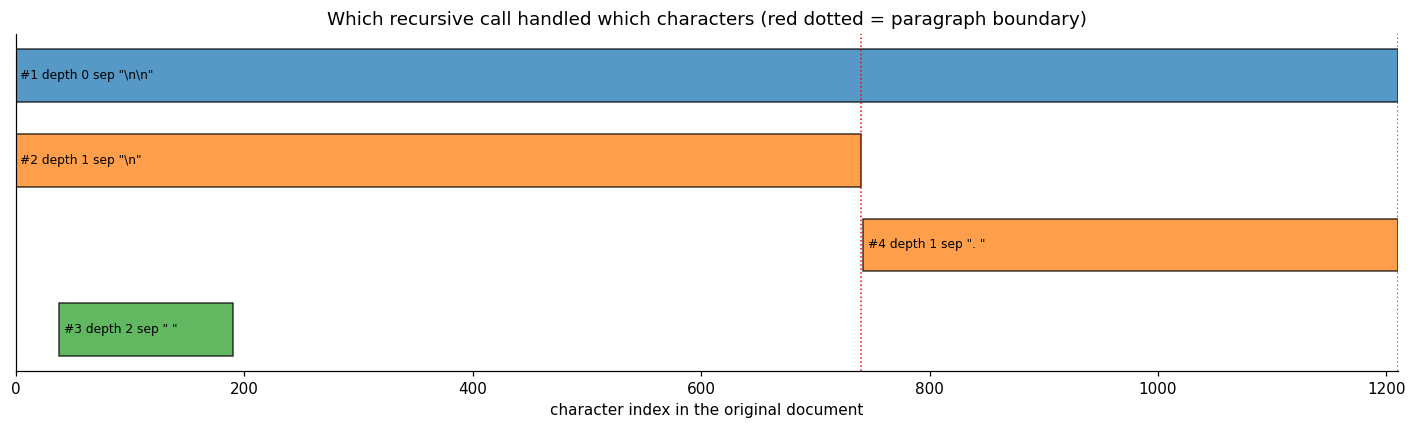

In [18]:
def plot_call_ownership(result):
    n = len(result.text)
    calls = sorted(result.calls.values(), key=lambda c: (c["depth"], c["id"]))
    fig, ax = plt.subplots(figsize=(13, 0.55 * len(calls) + 1.8))
    cmap = plt.get_cmap("tab10")
    for row, c in enumerate(calls):
        ax.barh(row, c["end"] - c["start"], left=c["start"], color=cmap(c["depth"] % 10), alpha=.75, edgecolor="k", height=.62)
        ax.text(c["start"] + 4, row, f"#{c['id']} depth {c['depth']} sep {json.dumps(c['separator'])}", va="center", fontsize=8)
    ax.set_yticks([]); ax.set_xlim(0, n); ax.invert_yaxis(); ax.set_xlabel("character index in the original document")
    for s, e in PARA_SPANS: ax.axvline(e, color="red", ls=":", lw=1)
    ax.set_title("Which recursive call handled which characters (red dotted = paragraph boundary)")
    plt.tight_layout(); plt.show()
plot_call_ownership(demo)

## 11. Merge Process

Splitting makes pieces **smaller**. Merging packs them **back together** so that chunks are as informative as possible without exceeding `chunk_size`. Without merging, a document cut at `"\n"` would become dozens of one-line "chunks" such as `| Green Tea | Small | 1.80 |`, which is far too little context for retrieval.

### Raw split pieces vs. final chunks

The left table lists every *leaf piece* (a piece that fit and was buffered). The right table shows which final chunk(s) they were merged into. Note that a piece can appear in **two** chunks: that is the overlap.

In [19]:
def display_pieces_vs_chunks(result):
    leaf = [r for c in result.calls.values() for r in c["pieces"] if r["action"] == "BUFFER"]
    leaf.sort(key=lambda r: r["start"])
    df = pd.DataFrame([{"piece": r["pid"], "start": r["start"], "length": r["length"],
                        "→ final chunk(s)": ", ".join(map(str, r["chunk_ids"])) or "—", "text": q(r["text"], 55)} for r in leaf])
    print(f"RAW SPLIT PIECES (leaves of the recursion): {len(leaf)} pieces, mean length {np.mean([r['length'] for r in leaf]):.1f}")
    display(df.style.hide(axis="index"))
    print(f"\nFINAL CHUNKS: {len(result.chunks)} chunks, mean length {np.mean([len(c) for c in result.chunks]):.1f}")
    display_chunk_table(result)
display_pieces_vs_chunks(demo)

RAW SPLIT PIECES (leaves of the recursion): 45 pieces, mean length 25.8


piece,start,length,→ final chunk(s),text
#2.P0,0,37,0,"""## Maple Hall Student Café & Services"""
#3.P0,38,5,1,"""Maple"""
#3.P1,44,4,1,"""Hall"""
#3.P2,49,4,1,"""Café"""
#3.P3,54,6,1,"""serves"""
#3.P4,61,9,1,"""students,"""
#3.P5,71,5,1,"""staff"""
#3.P6,77,3,1,"""and"""
#3.P7,81,8,1,"""visitors"""
#3.P8,90,2,1,"""on"""



FINAL CHUNKS: 12 chunks, mean length 101.1


Chunk,start,end,length,overlap w/ prev,from call,depth,pieces merged,preview
0,0,37,37,0,#2,1,1,"""## Maple Hall Student Café & Services"""
1,38,180,142,0,#3,2,23,"""Maple Hall Café serves student … eals, quiet seating and campus"""
2,162,190,28,18,#3,2,4,"""seating and campus printing."""
3,191,314,123,0,#2,1,5,"""MENU\n- Veggie Wrap ........ 5. … em | Size | Price |"""
4,315,454,139,0,#2,1,4,"""|---------------|--------|---- … uit Salad | Bowl | 3.40 |"""
5,455,593,138,0,#2,1,3,"""Dietary options:\n[x] Vegetaria … at 09:00-14:00; closed Sunday."""
6,594,740,146,0,#2,1,2,"""Policy: Reusable cups receive … iry or sesame before ordering."""
7,742,823,81,0,#4,1,1,"""Many universities now treat th … xtension of the learning space"""
8,825,930,105,0,#4,1,1,"""Students gather there between … and decide what to study next"""
9,932,1035,103,0,#4,1,1,"""A reliable café reduces the ti … e cup schemes also lower waste"""


### Every merge decision, in detail

Each line pair below is one decision of `_merge`. The rule: *"If current + separator + next piece would exceed `chunk_size`, finalise the current chunk; otherwise append."* When a chunk is finalised, the front pieces are dropped until at most `chunk_overlap` characters remain; those remaining pieces become the **start of the next chunk** (the overlap).

In [20]:
def display_merge_log(result, group=None, limit=None):
    steps = [s for s in result.merge_steps if group is None or s["group"] == group]
    for s in steps[:limit]:
        print("MERGE STEP  (group %d, call #%d)" % (s["group"], s["call"]))
        print(f"  Current chunk pieces : {s['current'] or '— empty —'}")
        print(f"  Current length       : {s['current_len']}")
        print(f"  Next piece           : {s['piece']}  (length {s['piece_len']})")
        print(f"  Separator length     : {s['sep_len']}")
        print(f"  Combined length      : {s['current_len']} + {s['piece_len']} + {s['sep_len']} = {s['combined']}")
        print(f"  Chunk size           : {s['chunk_size']}")
        print(f"  Decision             : {s['decision']}   ({s['reason']})")
        if s["decision"] == "REJECT" and s["closed_chunk"]:
            print(f"  → finalised a chunk of {s['closed_chunk'][0]} chars from {s['closed_chunk'][1]}")
            print(f"  → overlap: dropped {s['dropped']}, kept {s['retained']} = {s['retained_len']} chars (limit {result.chunk_overlap}); they start the next chunk")
        print()
    if limit and len(steps) > limit: print(f"... {len(steps)-limit} more steps (call display_merge_log(demo) for all).")

print("Showing the first merge group; every group is available via display_merge_log(demo, group=N).")
display_merge_log(demo, group=1, limit=8)

Showing the first merge group; every group is available via display_merge_log(demo, group=N).
MERGE STEP  (group 1, call #2)
  Current chunk pieces : — empty —
  Current length       : 0
  Next piece           : #2.P0  (length 37)
  Separator length     : 0
  Combined length      : 0 + 37 + 0 = 37
  Chunk size           : 150
  Decision             : ACCEPT   (37 ≤ 150: fits, so the piece joins the current chunk)



### "Where did this chunk come from?" (full provenance)

`trace_chunk` answers the central question of the notebook by walking **backwards**: final chunk → merge group → pieces → recursive call → chain of parent calls → separator decisions → original character range.

In [21]:
def trace_chunk(result, chunk_id, width=100):
    c = result.chunks[chunk_id]
    print("═" * 78); print(f"WHERE DID CHUNK {chunk_id} COME FROM?"); print("═" * 78)
    print(f"FINAL CHUNK {chunk_id}: {len(c)} chars, document span [{c.start}:{c.end}], exact slice of the original: {c.exact_slice}")
    print(textwrap.indent(textwrap.fill(q(c.text, 200), width), "    "))
    steps = [s for s in result.merge_steps if s["group"] == c.group]
    print(f"\n   ↑ produced by MERGE GROUP {c.group} inside call #{c.call}. Pieces merged: {c.piece_ids}")
    for s in steps:
        closes = s["closed_chunk"] is not None and s["closed_chunk"][1] == c.piece_ids
        if closes: tag = "this REJECT closed this chunk"
        elif s["piece"] in c.piece_ids and s["decision"] == "ACCEPT": tag = "ACCEPT: the piece joined this chunk"
        elif s["piece"] in c.piece_ids: tag = "this piece opened this chunk (it overflowed the previous chunk, which was closed)"
        else: continue
        print(f"       merge step: piece {s['piece']} → {s['decision']} ({s['combined']} vs {s['chunk_size']}): {tag}")
    print("\n   ↑ the pieces came from splitting at the separators below (walking up the call chain):")
    cid = c.call; chain = []
    while cid is not None:
        call = result.calls[cid]; chain.append(call); cid = call["parent"]
    for call in chain:
        print(f"       call #{call['id']} (depth {call['depth']}): {call['origin']}; {call['input_len']} chars; separator {json.dumps(call['separator'])}"
              + (f"; skipped {[json.dumps(x) for x in call['skipped']]}" if call["skipped"] else ""))
    print("   ↑ ROOT: the original document (", len(result.text), "chars )")
    if c.overlap_prev: print(f"\n   Overlap: the first {c.overlap_prev} characters repeat the end of chunk {chunk_id-1}: {q(result.text[c.start:c.start+c.overlap_prev], 80)}")

trace_chunk(demo, 3)
trace_chunk(demo, len(demo.chunks) - 1)

══════════════════════════════════════════════════════════════════════════════
WHERE DID CHUNK 3 COME FROM?
══════════════════════════════════════════════════════════════════════════════
FINAL CHUNK 3: 123 chars, document span [191:314], exact slice of the original: True
    "MENU\n- Veggie Wrap ........ 5.50\n- Chicken Rice Bowl .. 6.75\n- Lentil Soup ........ 3.25\n| Item
    | Size   | Price |"

   ↑ produced by MERGE GROUP 3 inside call #2. Pieces merged: ['#2.P2', '#2.P3', '#2.P4', '#2.P5', '#2.P6']
       merge step: piece #2.P2 → ACCEPT (4 vs 150): ACCEPT: the piece joined this chunk
       merge step: piece #2.P3 → ACCEPT (32 vs 150): ACCEPT: the piece joined this chunk
       merge step: piece #2.P4 → ACCEPT (60 vs 150): ACCEPT: the piece joined this chunk
       merge step: piece #2.P5 → ACCEPT (88 vs 150): ACCEPT: the piece joined this chunk
       merge step: piece #2.P6 → ACCEPT (123 vs 150): ACCEPT: the piece joined this chunk
       merge step: piece #2.P7 → REJECT (158 

## 12. Chunk Overlap

### Where does the overlap number come from?

We never pick the overlap arbitrarily. It is **derived from chunk size**:

```text
overlap = round(chunk_size × overlap_ratio)
```

With `overlap_ratio = 0.15`, a chunk size of 150 gives an overlap budget of 22 characters.

### What overlap is *for*

If a fact sits on a chunk boundary, for example a question whose answer begins at the end of chunk *n* and finishes at the start of chunk *n+1*, neither chunk alone contains the whole answer. Repeating a little text across the boundary gives such a fact a chance of landing complete inside at least one chunk.

### What overlap *costs*

Overlap duplicates text. More overlap means more characters to embed and store, more near-duplicate chunks competing in the top-k, and redundancy in the prompt. Too much overlap is wasteful; we test this in §15.

### How overlap is produced in the algorithm

Look at the merge log above: when a chunk is closed, `_merge` removes pieces from the *front* of the current chunk until at most `chunk_overlap` characters are left. Those surviving pieces start the next chunk. Consequences: (1) overlap comes in **whole pieces**, so the real overlap is *≤ budget*; (2) if the last piece alone is longer than the budget, the overlap is 0.

In [22]:
def display_overlap(result, show_text=True):
    rows = []
    print(f"Overlap budget = round({result.chunk_size} × {OVERLAP_RATIO}) = {result.chunk_overlap} characters\n")
    for a, b in zip(result.chunks[:-1], result.chunks[1:]):
        ov = max(0, a.end - b.start)
        rows.append({"between": f"{a.chunk_id} → {b.chunk_id}", "chunk A span": f"{a.start}–{a.end}", "chunk B span": f"{b.start}–{b.end}",
                     "overlap chars": ov, "budget used": f"{ov}/{result.chunk_overlap}", "shared text": q(result.text[b.start:a.end], 60) if ov else "— none —"})
    display(pd.DataFrame(rows).style.hide(axis="index"))
    if show_text:
        for a, b in zip(result.chunks[:-1], result.chunks[1:]):
            ov = max(0, a.end - b.start)
            if ov == 0: continue
            scale = 60 / len(result.text)
            la, lb = int(a.start * scale), int(a.end * scale); ob, oe = int(b.start * scale), max(int(a.end * scale), int(b.start * scale) + 1)
            bar_a = " " * la + "[" + "." * max(1, lb - la - 1) + "]"
            bar_b = " " * ob + "[" + "=" * max(1, oe - ob - 1) + "]" + "." * max(0, int(b.end * scale) - oe)
            print(f"Chunk {a.chunk_id}:  {bar_a}\nOverlap: {' ' * ob}{'=' * max(1, oe - ob)}   ← {ov} chars repeated\nChunk {b.chunk_id}:  {bar_b}\n   shared text: {q(result.text[b.start:a.end], 90)}\n")
display_overlap(demo)

Overlap budget = round(150 × 0.15) = 22 characters



between,chunk A span,chunk B span,overlap chars,budget used,shared text
0 → 1,0–37,38–180,0,0/22,— none —
1 → 2,38–180,162–190,18,18/22,"""seating and campus"""
2 → 3,162–190,191–314,0,0/22,— none —
3 → 4,191–314,315–454,0,0/22,— none —
4 → 5,315–454,455–593,0,0/22,— none —
5 → 6,455–593,594–740,0,0/22,— none —
6 → 7,594–740,742–823,0,0/22,— none —
7 → 8,742–823,825–930,0,0/22,— none —
8 → 9,825–930,932–1035,0,0/22,— none —
9 → 10,932–1035,1037–1180,0,0/22,— none —


Chunk 1:   [......]
Overlap:         =   ← 18 chars repeated
Chunk 2:          [=]
   shared text: "seating and campus"



## 13. Character Boundary Visualization

For every final chunk we know the **exact character span** in the original document, because our splitter tracks offsets (this is a feature of our implementation: we do not search for the text afterwards). The picture below places each chunk on the 0–1210 axis. Darker bands are overlap; the dotted red line marks the paragraph boundary.

Original document: 0──────────────────────────────────────────────────────────────────1210
Chunk  0  ──   0–37
Chunk  1    ────────   38–180
Chunk  2           ─   162–190   ↑ overlap 18
Chunk  3             ───────   191–314
Chunk  4                    ────────   315–454
Chunk  5                            ────────   455–593
Chunk  6                                    ────────   594–740
Chunk  7                                            ─────   742–823
Chunk  8                                                 ──────   825–930
Chunk  9                                                       ──────   932–1035
Chunk 10                                                             ─────────   1037–1180
Chunk 11                                                                      ──   1182–1210


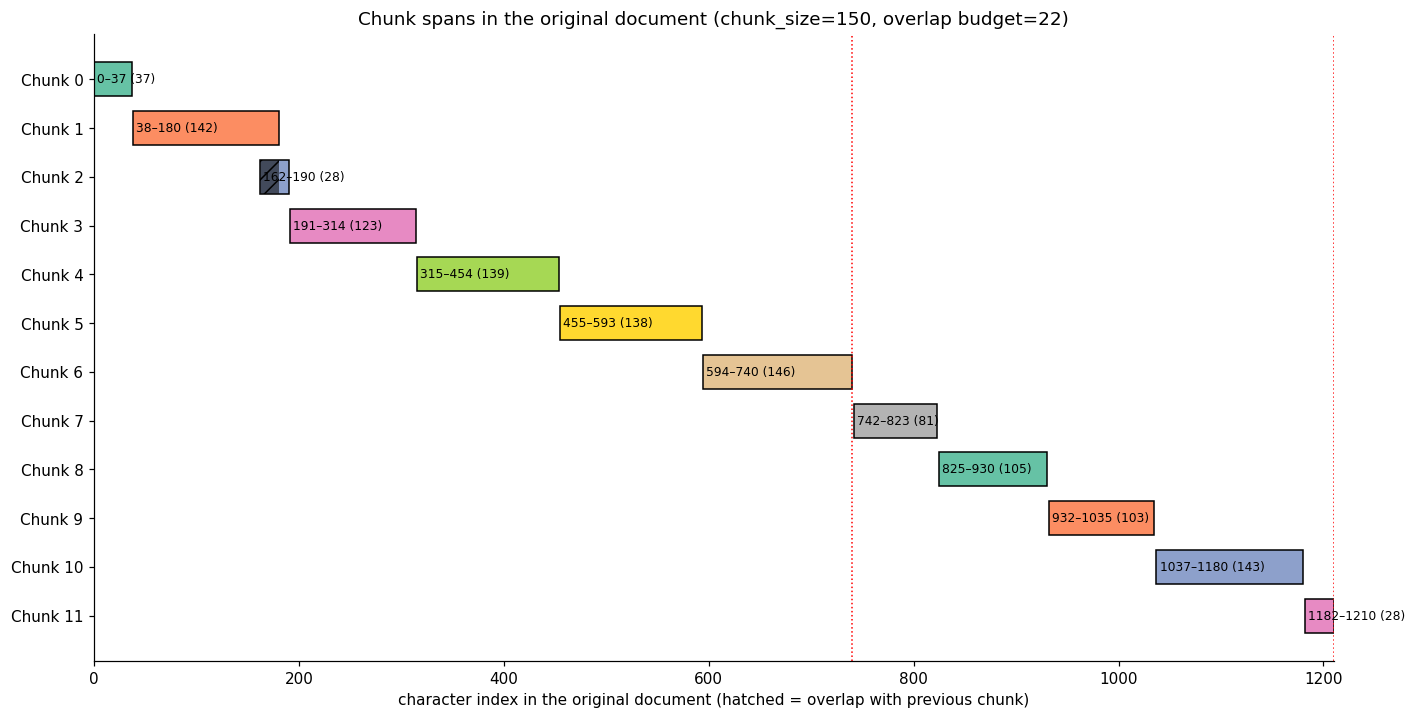

In [23]:
def display_character_ranges(result):
    n = len(result.text)
    for c in result.chunks:
        a, b = int(c.start / n * 70), max(int(c.start / n * 70) + 1, int(c.end / n * 70))
        print(f"Chunk {c.chunk_id:>2}  {' ' * a}{'─' * (b - a)}   {c.start}–{c.end}" + (f"   ↑ overlap {c.overlap_prev}" if c.overlap_prev else ""))

def plot_boundaries(result, title=None):
    n = len(result.text); fig, ax = plt.subplots(figsize=(13, 0.42 * len(result.chunks) + 1.6)); cmap = plt.get_cmap("Set2")
    for c in result.chunks:
        ax.barh(c.chunk_id, c.end - c.start, left=c.start, color=cmap(c.chunk_id % 8), edgecolor="k", height=.7)
        if c.overlap_prev: ax.barh(c.chunk_id, c.overlap_prev, left=c.start, color="#111", alpha=.6, height=.7, hatch="//")
        ax.text(c.start + 3, c.chunk_id, f"{c.start}–{c.end} ({len(c)})", va="center", fontsize=8)
    for s, e in PARA_SPANS: ax.axvline(e, color="red", ls=":", lw=1)
    ax.set_yticks(range(len(result.chunks))); ax.set_yticklabels([f"Chunk {c.chunk_id}" for c in result.chunks]); ax.invert_yaxis()
    ax.set_xlim(0, n); ax.set_xlabel("character index in the original document (hatched = overlap with previous chunk)")
    ax.set_title(title or f"Chunk spans in the original document (chunk_size={result.chunk_size}, overlap budget={result.chunk_overlap})")
    plt.tight_layout(); plt.show()

print(f"Original document: 0{'─' * 66}{len(DOCUMENT)}"); display_character_ranges(demo); plot_boundaries(demo)

**What to notice:** chunk boundaries follow the *structure* of the text (line ends, sentence ends) rather than falling at multiples of 150. Because merging only accepts whole pieces, many chunks are noticeably shorter than 150. The paragraph boundary (red dotted line) is never crossed by a chunk when the split at `"\n\n"` separated the two paragraphs into different calls: pieces from different calls are never merged together, so recursion also acts as a **barrier**.

## 14. Chunk Size Experiments

The 1210-character document is tiny, so the interesting range of chunk sizes is roughly **150 to 400 characters**: at 150 almost every level of the separator hierarchy fires, while at 400 the whole first paragraph is already just two chunks. For *each* size the **full custom recursive splitter** runs (not a shortcut), with overlap computed as `round(chunk_size × 0.15)`.

For every run we record the structural metrics requested in the brief:

| Metric | Meaning |
|---|---|
| `n_chunks`, `avg/min/max/std_len` | how many chunks and how uniform they are |
| `pct_near_target` | % of chunks whose length is between 80% and 100% of `chunk_size` ("well filled") |
| `n_calls`, `max_depth`, `n_transitions` | work done by the recursion (calls, deepest level, number of "go to the next separator" decisions) |
| `n_merge_ops` | number of ACCEPT/REJECT merge decisions |
| `overlap_chars` | total characters duplicated between consecutive chunks |
| `granularity_pct_doc` | how much of the document one average chunk covers: our *estimate of retrieval granularity* |

In [24]:
EXPERIMENT = {}                      # chunk_size -> SplitResult (kept for all later sections)
for cs in CHUNK_SIZES:
    EXPERIMENT[cs] = TracingRecursiveSplitter(cs, overlap_for(cs)).split(DOCUMENT)
    assert all(c.exact_slice for c in EXPERIMENT[cs].chunks), "every chunk must be an exact slice of the document"

struct_df = pd.DataFrame([r.stats() for r in EXPERIMENT.values()])
struct_df.insert(2, "overlap_ratio", [r.chunk_overlap / r.chunk_size for r in EXPERIMENT.values()])

def display_structural_table(df):
    nice = df.rename(columns={"chunk_size": "chunk size", "n_chunks": "# chunks", "avg_len": "avg len", "min_len": "min len", "max_len": "max len",
                              "std_len": "std len", "pct_near_target": "% near target", "n_calls": "# calls", "max_depth": "max depth",
                              "n_transitions": "# separator transitions", "n_merge_ops": "# merge ops", "overlap_chars": "overlap chars (total)",
                              "n_oversize": "# oversize", "granularity_pct_doc": "granularity (% of doc / chunk)", "overlap_ratio": "overlap ratio"})
    display(nice.style.format({"overlap ratio": "{:.2f}", "avg len": "{:.1f}", "std len": "{:.1f}", "% near target": "{:.0f}%",
                               "granularity (% of doc / chunk)": "{:.1f}%"}).hide(axis="index").background_gradient(cmap="Blues", subset=["# chunks"]))
display_structural_table(struct_df)

chunk size,overlap,overlap ratio,# chunks,avg len,min len,max len,std len,% near target,# calls,max depth,# separator transitions,# merge ops,overlap chars (total),# oversize,granularity (% of doc / chunk)
150,22,0.15,12,101.1,28,146,44.7,50%,4,2,3,45,18,0,8.4%
200,30,0.15,8,150.6,65,195,47.9,50%,3,1,2,22,4,0,12.4%
250,38,0.15,7,181.3,28,248,69.6,57%,3,1,2,22,66,0,15.0%
300,45,0.15,5,246.4,173,293,45.6,60%,3,1,2,22,27,0,20.4%
400,60,0.15,4,310.0,86,390,129.4,75%,3,1,2,22,34,0,25.6%


/tmp/ipykernel_130332/888187940.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([[len(c) for c in EXPERIMENT[cs].chunks] for cs in CHUNK_SIZES], labels=CHUNK_SIZES, showmeans=True)


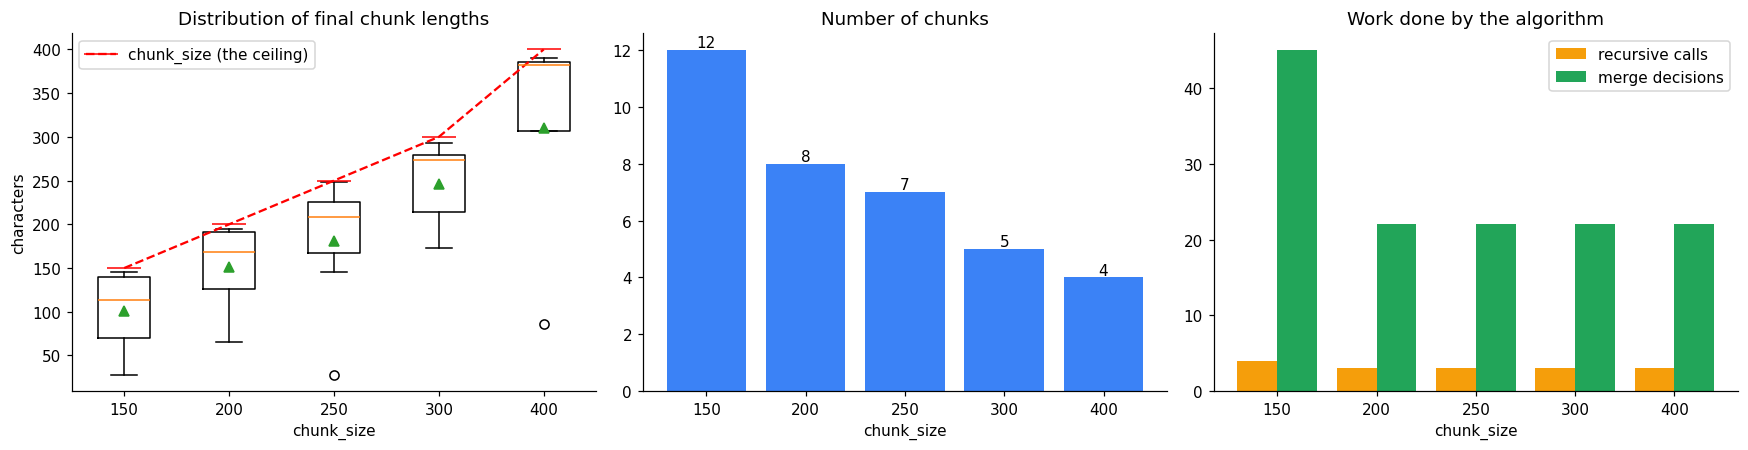

chunk size,calls per depth,separators actually used (calls)
150,"{0: np.int64(1), 1: np.int64(2), 2: np.int64(1)}","{'""\\n\\n""': np.int64(1), '""\\n""': np.int64(1), '"" ""': np.int64(1), '"". ""': np.int64(1)}"
200,"{0: np.int64(1), 1: np.int64(2)}","{'""\\n\\n""': np.int64(1), '""\\n""': np.int64(1), '"". ""': np.int64(1)}"
250,"{0: np.int64(1), 1: np.int64(2)}","{'""\\n\\n""': np.int64(1), '""\\n""': np.int64(1), '"". ""': np.int64(1)}"
300,"{0: np.int64(1), 1: np.int64(2)}","{'""\\n\\n""': np.int64(1), '""\\n""': np.int64(1), '"". ""': np.int64(1)}"
400,"{0: np.int64(1), 1: np.int64(2)}","{'""\\n\\n""': np.int64(1), '""\\n""': np.int64(1), '"". ""': np.int64(1)}"


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].boxplot([[len(c) for c in EXPERIMENT[cs].chunks] for cs in CHUNK_SIZES], labels=CHUNK_SIZES, showmeans=True)
axes[0].plot(range(1, len(CHUNK_SIZES) + 1), CHUNK_SIZES, "r--", marker="_", ms=22, label="chunk_size (the ceiling)")
axes[0].set_title("Distribution of final chunk lengths"); axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("characters"); axes[0].legend()
axes[1].bar([str(cs) for cs in CHUNK_SIZES], struct_df["n_chunks"], color="#3b82f6")
for i, v in enumerate(struct_df["n_chunks"]): axes[1].text(i, v + .1, str(v), ha="center")
axes[1].set_title("Number of chunks"); axes[1].set_xlabel("chunk_size")
x = np.arange(len(CHUNK_SIZES)); axes[2].bar(x - .2, struct_df["n_calls"], .4, label="recursive calls", color="#f59e0b")
axes[2].bar(x + .2, struct_df["n_merge_ops"], .4, label="merge decisions", color="#22a559")
axes[2].set_xticks(x); axes[2].set_xticklabels(CHUNK_SIZES); axes[2].set_title("Work done by the algorithm"); axes[2].set_xlabel("chunk_size"); axes[2].legend()
plt.tight_layout(); plt.show()

# How deep did the recursion go for each size?
rows = []
for cs, r in EXPERIMENT.items():
    per_depth = pd.Series([c["depth"] for c in r.calls.values()]).value_counts().sort_index()
    seps = pd.Series([json.dumps(c["separator"]) for c in r.calls.values()]).value_counts()
    rows.append({"chunk size": cs, "calls per depth": dict(per_depth), "separators actually used (calls)": dict(seps)})
display(pd.DataFrame(rows).style.hide(axis="index"))

### What the structural table tells us (and what it cannot)

The numbers above describe **how the document was cut**. For instance:

* larger `chunk_size` → fewer chunks, less recursion (fewer calls and fewer separator transitions), because more pieces fit after the first cut;
* `% near target` and `std len` describe how *evenly* chunks are filled; since merging only accepts whole pieces, they rarely hit the ceiling exactly.

But **structure is not quality.** A chunking with beautifully uniform chunk lengths might still split the answer to a question across two chunks. To judge usefulness we must test retrieval. That is the next part of the plan.

## 15. Selecting the Best Chunk Size

### The trade-off

| | **Small chunks** | **Large chunks** |
|---|---|---|
| Retrieval precision | ✔ focused vector, precise match | ✘ one vector blends several topics |
| Context per chunk | ✘ may lack the surrounding information | ✔ more self-contained |
| Number of chunks | ✘ more vectors, more storage and search work | ✔ fewer |
| Meaning | ✘ risk of fragmenting a fact | ✘ risk of dragging irrelevant text into the prompt |

There is no universally best size. It depends on the document and on the questions. So we use a **transparent heuristic** that combines two views:

```text
selection_score = 0.70 × retrieval_score + 0.30 × structure_score

retrieval_score = 0.50 × MRR + 0.30 × Recall@1 + 0.20 × Recall@3
structure_score = 0.50 × fill_ratio + 0.50 × uniformity
      fill_ratio = avg_chunk_length / chunk_size
      uniformity = 1 − min(1, std_length / avg_length)
```

The weights are **editable constants** (next cell) and deliberately favour retrieval, because chunking exists to serve retrieval. Ties are broken in favour of **fewer chunks** (cheaper to store and search). The retrieval half of the score needs embeddings, so the final selection happens in §23. Here we prepare its ingredients: the test queries and the structural score.

### Test queries and ground truth

To measure retrieval we need questions *with known answers*. For each query we list **evidence strings**: short snippets of the document that together contain the answer. A chunk counts as **relevant** only if it contains *all* the evidence strings. Therefore, if a chunk size cuts the evidence in half, no chunk is relevant for that query at that size, which is exactly the failure mode that chunk size can cause.

In [26]:
W_RETRIEVAL, W_STRUCTURE = 0.70, 0.30
W_MRR, W_R1, W_R3 = 0.50, 0.30, 0.20
W_FILL, W_UNIF = 0.50, 0.50

QUERIES = [
    dict(id="Q1", kind="table",    question="How much does a green tea cost?",
         evidence=["Green Tea", "1.80"]),
    dict(id="Q2", kind="menu",     question="What is the price of the chicken rice bowl?",
         evidence=["Chicken Rice Bowl", "6.75"]),
    dict(id="Q3", kind="checkbox", question="Which dietary options are available, and is gluten-free offered?",
         evidence=["[x] Halal", "[ ] Gluten-free"]),
    dict(id="Q4", kind="paragraph 2 (prose)", question="Why do students spend time in the campus café between lectures?",
         evidence=["Students gather there between lectures"]),
    dict(id="Q5", kind="boundary-spanning", question="When does the café close on Saturday, and from what time is cash no longer accepted?",
         evidence=["Sat 09:00-14:00", "Cash is not accepted after 16:00"]),
    dict(id="Q6", kind="policy", question="Do I get a discount if I bring my own cup?",
         evidence=["Reusable cups receive a 0.30 discount"]),
]
# Verify programmatically that every evidence string really occurs in the document
for qd in QUERIES:
    for ev in qd["evidence"]:
        assert ev in DOCUMENT, f"{qd['id']}: evidence {ev!r} not found in the document"
    qd["evidence_span"] = (min(DOCUMENT.index(e) for e in qd["evidence"]), max(DOCUMENT.index(e) + len(e) for e in qd["evidence"]))

display(pd.DataFrame([{"id": d["id"], "tests": d["kind"], "question": d["question"], "evidence strings": d["evidence"],
                       "evidence span (chars)": f"{d['evidence_span'][0]}–{d['evidence_span'][1]} ({d['evidence_span'][1]-d['evidence_span'][0]})"}
                      for d in QUERIES]).style.hide(axis="index"))

def relevant_chunk_ids(result, evidence):
    return [c.chunk_id for c in result.chunks if all(e in c.text for e in evidence)]

# Does each chunk size keep each piece of evidence together in at least one chunk?  (the ceiling for any retriever)
integrity = pd.DataFrame({cs: {d["id"]: len(relevant_chunk_ids(EXPERIMENT[cs], d["evidence"])) for d in QUERIES} for cs in CHUNK_SIZES})
integrity.index.name = "query"; integrity.columns.name = "chunk_size"
print("Number of chunks that contain ALL evidence for each query (0 = the splitter cut the evidence apart → no retriever can succeed):")
display(integrity.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=2))
print("Share of queries answerable at all, per chunk size (upper bound for Recall@k):")
display((integrity.gt(0).mean() * 100).round(0).astype(int).astype(str).add("%").to_frame("answerable").T)

id,tests,question,evidence strings,evidence span (chars)
Q1,table,How much does a green tea cost?,"['Green Tea', '1.80']",387–416 (29)
Q2,menu,What is the price of the chicken rice bowl?,"['Chicken Rice Bowl', '6.75']",226–251 (25)
Q3,checkbox,"Which dietary options are available, and is gluten-free offered?","['[x] Halal', '[ ] Gluten-free']",488–514 (26)
Q4,paragraph 2 (prose),Why do students spend time in the campus café between lectures?,['Students gather there between lectures'],825–863 (38)
Q5,boundary-spanning,"When does the café close on Saturday, and from what time is cash no longer accepted?","['Sat 09:00-14:00', 'Cash is not accepted after 16:00']",562–673 (111)
Q6,policy,Do I get a discount if I bring my own cup?,['Reusable cups receive a 0.30 discount'],602–639 (37)


Number of chunks that contain ALL evidence for each query (0 = the splitter cut the evidence apart → no retriever can succeed):


chunk_size,150,200,250,300,400
query,,,,,
Q1,1,1,2,1,1
Q2,1,1,1,1,1
Q3,1,1,1,1,1
Q4,1,1,1,1,1
Q5,0,1,0,1,1
Q6,1,1,1,1,1


Share of queries answerable at all, per chunk size (upper bound for Recall@k):


chunk_size,150,200,250,300,400
answerable,83%,100%,83%,100%,100%


**Why the "evidence integrity" matrix matters.** It is computed *before* any embedding, using only the chunk boundaries. A `0` means: at this chunk size the splitter separated the pieces of evidence that a question needs, so **no embedding model or vector database can recover them in a single chunk**. This is the clearest demonstration that chunking decisions limit retrieval quality before retrieval even starts. Overlap is exactly the mechanism meant to reduce such losses.

In [27]:
def structure_score(stats):
    fill = stats["avg_len"] / stats["chunk_size"]
    unif = 1 - min(1.0, stats["std_len"] / stats["avg_len"])
    return W_FILL * fill + W_UNIF * unif, fill, unif

struct_rows = []
for cs in CHUNK_SIZES:
    s = EXPERIMENT[cs].stats(); sc, fill, unif = structure_score(s)
    struct_rows.append({"chunk size": cs, "fill ratio": fill, "uniformity": unif, "structure score": sc})
struct_scores = pd.DataFrame(struct_rows)
display(struct_scores.style.format({"fill ratio": "{:.3f}", "uniformity": "{:.3f}", "structure score": "{:.3f}"}).hide(axis="index"))

chunk size,fill ratio,uniformity,structure score
150,0.674,0.558,0.616
200,0.753,0.682,0.718
250,0.725,0.616,0.671
300,0.821,0.815,0.818
400,0.775,0.583,0.679


## 16. Embedding with MiniLM

### What is an embedding?

An **embedding** is a list of numbers (a *vector*) that represents the meaning of a text so that a computer can compare texts by geometry instead of by exact words.

```text
Text   →   Tokenizer   →   Transformer model (MiniLM)   →   Pooling   →   Vector
"Green Tea | 1.80"     ["green","tea","|","1",".","80"]    hidden states    [0.03, -0.11, 0.07, …]  (384 numbers)
```

* **Dimensionality** is the length of the vector. `all-MiniLM-L6-v2` always produces **384** numbers, whatever the text length. Think of 384 "axes of meaning"; no single axis is human-interpretable.
* **Why text becomes a vector:** neural networks work with numbers, and vectors let us measure *similarity* with simple arithmetic (angles between arrows).
* **Why similar texts get similar vectors:** the model was trained so that texts which mean similar things (for example paraphrases, or a question and its answer) end up pointing in similar directions. This is a *learned statistical tendency*, not a guarantee, which is why we measure retrieval instead of assuming it works.

The model runs **locally**. No embedding API is called. It is loaded **once** and all embeddings are cached.

In [28]:
class HashingEmbedder:
    """OFFLINE STAND-IN, NOT MiniLM. Used only if RAGLAB_ALLOW_FALLBACK_EMBEDDER=1 and MiniLM cannot be loaded.
    It hashes character 3-grams into 384 buckets: lexical similarity only, no semantics."""
    is_fallback = True; name = "HashingEmbedder (lexical stand-in, NOT MiniLM)"; dim = 384; tokenizer = None; max_seq_length = None
    def encode(self, texts):
        out = np.zeros((len(texts), self.dim), dtype=np.float32)
        for i, t in enumerate(texts):
            t = f"  {t.lower()}  "
            for j in range(len(t) - 2): out[i, zlib.crc32(t[j:j + 3].encode()) % self.dim] += 1.0
            n = np.linalg.norm(out[i]); out[i] /= (n if n else 1.0)
        return out

class MiniLMEmbedder:
    is_fallback = False
    def __init__(self, model_name):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_name)          # downloads once, then uses the local cache
        self.name = model_name; self.dim = self.model.get_sentence_embedding_dimension()
        self.tokenizer = self.model.tokenizer; self.max_seq_length = self.model.max_seq_length
    def encode(self, texts):
        return np.asarray(self.model.encode(list(texts), convert_to_numpy=True, show_progress_bar=False), dtype=np.float32)

def load_embedder():
    try:
        return MiniLMEmbedder(EMBED_MODEL)
    except Exception as e:
        if os.getenv("RAGLAB_ALLOW_FALLBACK_EMBEDDER") == "1":
            print(f"⚠ Could not load {EMBED_MODEL}: {type(e).__name__}: {str(e)[:150]}\n⚠ Using the lexical STAND-IN embedder because RAGLAB_ALLOW_FALLBACK_EMBEDDER=1. Results are NOT MiniLM results.")
            return HashingEmbedder()
        raise RuntimeError(
            f"Could not load the embedding model '{EMBED_MODEL}': {type(e).__name__}: {e}\n"
            "Possible causes: no internet on the first run (the model must be downloaded once), a missing package "
            "(pip install sentence-transformers), or a Hugging Face outage.\nFix the cause and re-run this cell. "
            "(Developers without network access may set RAGLAB_ALLOW_FALLBACK_EMBEDDER=1 to test the code path.)") from e

embedder = load_embedder()
EMB_CACHE = {}                                   # text -> vector (never embed the same text twice)

def embed_texts(texts):
    if isinstance(texts, str): texts = [texts]
    if any((not isinstance(t, str)) or not t.strip() for t in texts): raise ValueError("cannot embed empty / non-string text")
    todo = [t for t in dict.fromkeys(texts) if t not in EMB_CACHE]
    if todo:
        for t, v in zip(todo, embedder.encode(todo)): EMB_CACHE[t] = v
    return np.vstack([EMB_CACHE[t] for t in texts])

EMB_DIM = embedder.dim
print(f"Embedding model : {embedder.name}\nEmbedding dim   : {EMB_DIM}\nMax input length: {embedder.max_seq_length} tokens")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model : sentence-transformers/all-MiniLM-L6-v2
Embedding dim   : 384
Max input length: 256 tokens


/tmp/ipykernel_130332/1482876634.py:18: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.name = model_name; self.dim = self.model.get_sentence_embedding_dimension()


In [29]:
# ── Show what the model does to ONE chunk: Text → tokens → vector ─────────────
sample = EXPERIMENT[200].chunks[2].text
print("TEXT (one chunk):\n ", q(sample, 160))
if embedder.tokenizer is not None:
    toks = embedder.tokenizer.tokenize(sample)
    print(f"\nTOKENIZER → {len(toks)} word-piece tokens (model limit {embedder.max_seq_length}). First 15: {toks[:15]}")
else:
    print("\n(stand-in embedder: no tokenizer)")
vec = embed_texts(sample)[0]
print(f"\nEMBEDDING → numpy array  shape={vec.shape}  dtype={vec.dtype}  L2-norm={np.linalg.norm(vec):.4f}")
print("first 8 values:", np.round(vec[:8], 4), "...")
assert vec.shape == (EMB_DIM,)

# Do similar texts get similar vectors? (cosine similarity, computed properly in §21)
trio = ["How much does a green tea cost?", "Green Tea | Small | 1.80", "Students gather there between lectures to review notes"]
E = embed_texts(trio); E = E / np.linalg.norm(E, axis=1, keepdims=True)
print(f"\ncos(question, table row about the same item) = {E[0] @ E[1]:.3f}\ncos(question, unrelated prose sentence)     = {E[0] @ E[2]:.3f}")

TEXT (one chunk):
  "| Green Tea     | Small  | 1.80  |\n| Fruit Salad   | Bowl   | 3.40  |\nDietary options:\n[x] Vegetarian  [x] Halal  [ ] Gluten-free  [ ] Vegan"

TOKENIZER → 43 word-piece tokens (model limit 256). First 15: ['|', 'green', 'tea', '|', 'small', '|', '1', '.', '80', '|', '|', 'fruit', 'salad', '|', 'bowl']

EMBEDDING → numpy array  shape=(384,)  dtype=float32  L2-norm=1.0000
first 8 values: [ 0.0458 -0.0134  0.0394  0.0243 -0.0039  0.0657  0.0514 -0.031 ] ...

cos(question, table row about the same item) = 0.701
cos(question, unrelated prose sentence)     = 0.019


## 17. Embedding Visualization

A 384-dimensional space cannot be drawn, so we project it to 2D with **PCA** (principal component analysis): it finds the two directions along which the vectors vary most and plots each vector's coordinates along them. **Caution:** this is a *projection*. Points that look close in 2D may be far apart in 384D, and points that look far apart may be close along dimensions that PCA discarded. The plot is an intuition aid, not a measurement. The ranking in §21–22 uses all 384 dimensions.

For the walk-through (§17–22) we use a fixed **teaching configuration**, chunk size **200** (8-ish chunks: enough for a meaningful top-k, small enough to read). This is *not* a claim that 200 is best; that is decided in §23.

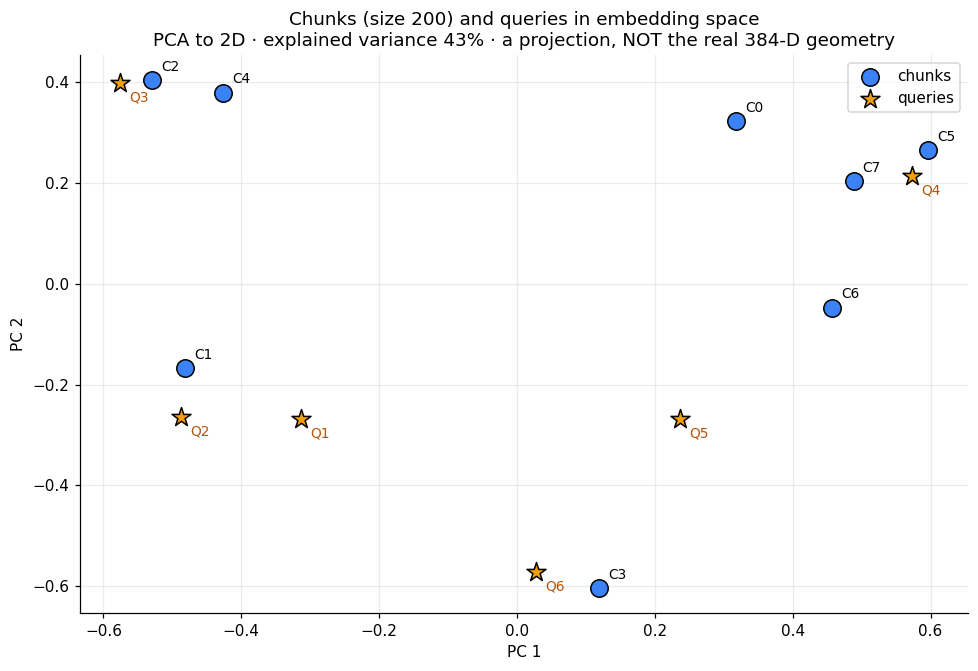

Chunk legend:


Chunk,start,end,length,overlap w/ prev,from call,depth,pieces merged,preview
0,0,195,195,0,#2,1,3,"""## Maple Hall Student Café & Servic … t seating and campus printing.\nMENU"""
1,191,384,193,4,#2,1,7,"""MENU\n- Veggie Wrap ........ 5.50\n- … \n| Filter Coffee | Medium | 2.20 |"""
2,385,525,140,0,#2,1,4,"""| Green Tea | Small | 1.80 |\n … ] Halal [ ] Gluten-free [ ] Vegan"""
3,526,674,148,0,#2,1,2,"""Opening hours: Mon-Fri 08:00-18:00; … . Cash is not accepted after 16:00."""
4,675,740,65,0,#2,1,1,"""Allergens: ask staff about nuts, dairy or sesame before ordering."""
5,742,930,188,0,#3,1,2,"""Many universities now treat the cam … tings and decide what to study next"""
6,932,1122,190,0,#3,1,2,"""A reliable café reduces the time sp … nformal ambassadors for the service"""
7,1124,1210,86,0,#3,1,2,"""Good cafés therefore support both w … rning. Quiet corners help revision."""


In [30]:
WALK_CHUNK_SIZE = 200
walk = EXPERIMENT[WALK_CHUNK_SIZE]
walk_vecs = embed_texts([c.text for c in walk.chunks])
query_vecs = embed_texts([d["question"] for d in QUERIES])

def plot_embedding_projection(chunk_vecs, chunk_labels, q_vecs, q_labels, title, highlight=None):
    from sklearn.decomposition import PCA
    allv = np.vstack([chunk_vecs, q_vecs]); pca = PCA(n_components=2, random_state=SEED).fit(allv); P = pca.transform(allv)
    nc = len(chunk_vecs); fig, ax = plt.subplots(figsize=(9, 6.2))
    ax.scatter(P[:nc, 0], P[:nc, 1], s=130, c="#3b82f6", edgecolor="k", label="chunks", zorder=3)
    ax.scatter(P[nc:, 0], P[nc:, 1], s=170, c="#f59e0b", marker="*", edgecolor="k", label="queries", zorder=3)
    for (x, y), lab in zip(P[:nc], chunk_labels): ax.annotate(lab, (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
    for (x, y), lab in zip(P[nc:], q_labels): ax.annotate(lab, (x, y), textcoords="offset points", xytext=(6, -12), fontsize=9, color="#b45309")
    if highlight is not None:
        for qi, ci in highlight: ax.plot([P[nc + qi, 0], P[ci, 0]], [P[nc + qi, 1], P[ci, 1]], "g--", lw=1, zorder=2)
    ax.set_title(f"{title}\nPCA to 2D · explained variance {pca.explained_variance_ratio_.sum()*100:.0f}% · a projection, NOT the real 384-D geometry")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

plot_embedding_projection(walk_vecs, [f"C{c.chunk_id}" for c in walk.chunks], query_vecs, [d["id"] for d in QUERIES],
                          f"Chunks (size {WALK_CHUNK_SIZE}) and queries in embedding space")
print("Chunk legend:"); display_chunk_table(walk, preview=70)

## 18. Qdrant Setup

**Qdrant** is a vector database: it stores vectors and quickly finds the stored vectors most similar to a query vector. We use the Python client in **local in-memory mode** (`QdrantClient(":memory:")`): no server, no account. Set `QDRANT_PATH = "./qdrant_local_db"` in the configuration cell for local on-disk persistence instead.

```text
Chunk text
   ↓  embed (MiniLM)
Vector (384 floats)
   ↓  wrap
Qdrant POINT  =  id  +  vector  +  payload (the metadata dictionary)
   ↓  stored in
Qdrant COLLECTION  (configured with: vector size 384, distance = COSINE)
```

* The **collection** declares the vector dimensionality and the distance function. Vectors of a different size are rejected.
* The **payload** is arbitrary JSON stored next to the vector: we keep the chunk text and provenance (character span, recursion depth, paragraph, chunk size). That payload is how a search hit gets turned back into text for the prompt, and how every retrieved chunk can be traced to the original document.

In [31]:
try:
    from qdrant_client import QdrantClient, models
    qdrant = QdrantClient(":memory:") if QDRANT_PATH is None else QdrantClient(path=QDRANT_PATH)
except Exception as e:
    raise RuntimeError(f"Qdrant initialisation failed: {type(e).__name__}: {e}\n"
                       "Try: pip install -U qdrant-client.  If you set QDRANT_PATH, make sure the folder is writable "
                       "and not locked by another notebook.") from e
print("Qdrant client ready · mode:", "in-memory" if QDRANT_PATH is None else f"local disk at {QDRANT_PATH}", "· qdrant-client", pkg_version("qdrant-client"))

def paragraphs_of(start, end):
    return "+".join(str(i + 1) for i, (s, e) in enumerate(PARA_SPANS) if start < e and end > s)

def chunk_payload(result, c, source="maple_hall_cafe.txt"):
    return {"chunk_id": c.chunk_id, "text": c.text, "source": source, "paragraph": paragraphs_of(c.start, c.end),
            "recursion_depth": c.depth, "start_char": c.start, "end_char": c.end, "chunk_size": result.chunk_size,
            "chunk_overlap": result.chunk_overlap, "recursive_call": c.call, "overlap_with_previous": c.overlap_prev}

def build_collection(name, result, vectors):
    """(Re)create a collection and upsert one point per chunk."""
    try: qdrant.delete_collection(name)
    except Exception: pass
    qdrant.create_collection(collection_name=name, vectors_config=models.VectorParams(size=vectors.shape[1], distance=models.Distance.COSINE))
    points = [models.PointStruct(id=c.chunk_id, vector=vectors[i].tolist(), payload=chunk_payload(result, c)) for i, c in enumerate(result.chunks)]
    qdrant.upsert(collection_name=name, points=points, wait=True)
    return points

def qdrant_search(name, qvec, k):
    """Version-tolerant search: new API `query_points`, old API `search`."""
    if hasattr(qdrant, "query_points"):
        return qdrant.query_points(collection_name=name, query=list(map(float, qvec)), limit=k, with_payload=True).points
    return qdrant.search(collection_name=name, query_vector=list(map(float, qvec)), limit=k, with_payload=True)

Qdrant client ready · mode: in-memory · qdrant-client 1.18.0


## 19. Storing Chunks

In [32]:
WALK_COLLECTION = f"walkthrough_{WALK_CHUNK_SIZE}"
points = build_collection(WALK_COLLECTION, walk, walk_vecs)

info = qdrant.get_collection(WALK_COLLECTION)
vparams = info.config.params.vectors
print("COLLECTION CONFIGURATION")
print("  name            :", WALK_COLLECTION)
print("  vector size     :", getattr(vparams, "size", vparams))
print("  distance        :", getattr(vparams, "distance", "?"))
print("  points stored   :", qdrant.count(collection_name=WALK_COLLECTION, exact=True).count)
assert getattr(vparams, "size", EMB_DIM) == EMB_DIM

print("\nINSERTED POINTS (payload without the long text):")
display(pd.DataFrame([{k: v for k, v in p.payload.items() if k != "text"} | {"vector dims": len(p.vector)} for p in points]).style.hide(axis="index"))

stored = qdrant.retrieve(collection_name=WALK_COLLECTION, ids=[2], with_vectors=True, with_payload=True)[0]
print("\nINSPECTING ONE STORED POINT (id=2)")
print("  id      :", stored.id)
print("  vector  : first 6 of", len(stored.vector), "values →", np.round(stored.vector[:6], 4))
print("  payload :"); print(textwrap.indent(json.dumps(stored.payload, indent=2, ensure_ascii=False), "     "))

COLLECTION CONFIGURATION
  name            : walkthrough_200
  vector size     : 384
  distance        : Cosine
  points stored   : 8

INSERTED POINTS (payload without the long text):


chunk_id,source,paragraph,recursion_depth,start_char,end_char,chunk_size,chunk_overlap,recursive_call,overlap_with_previous,vector dims
0,maple_hall_cafe.txt,1,1,0,195,200,30,2,0,384
1,maple_hall_cafe.txt,1,1,191,384,200,30,2,4,384
2,maple_hall_cafe.txt,1,1,385,525,200,30,2,0,384
3,maple_hall_cafe.txt,1,1,526,674,200,30,2,0,384
4,maple_hall_cafe.txt,1,1,675,740,200,30,2,0,384
5,maple_hall_cafe.txt,2,1,742,930,200,30,3,0,384
6,maple_hall_cafe.txt,2,1,932,1122,200,30,3,0,384
7,maple_hall_cafe.txt,2,1,1124,1210,200,30,3,0,384



INSPECTING ONE STORED POINT (id=2)
  id      : 2
  vector  : first 6 of 384 values → [ 0.0458 -0.0134  0.0394  0.0243 -0.0039  0.0657]
  payload :
     {
       "chunk_id": 2,
       "text": "| Green Tea     | Small  | 1.80  |\n| Fruit Salad   | Bowl   | 3.40  |\nDietary options:\n[x] Vegetarian  [x] Halal  [ ] Gluten-free  [ ] Vegan",
       "source": "maple_hall_cafe.txt",
       "paragraph": "1",
       "recursion_depth": 1,
       "start_char": 385,
       "end_char": 525,
       "chunk_size": 200,
       "chunk_overlap": 30,
       "recursive_call": 2,
       "overlap_with_previous": 0
     }


## 20. Query Embedding

At question time the same embedding model turns the **user's question** into a vector in the **same 384-dimensional space** as the chunks. This is what makes a comparison possible: a question and a chunk are both just points (arrows) in one shared space.

```text
USER QUERY → QUERY EMBEDDING → VECTOR DIMENSION → QDRANT SEARCH → TOP-K CHUNKS → SIMILARITY SCORES → RETRIEVED CONTEXT
```

In [33]:
def preview(text, n=70): return q(text, n)

def show_query_embedding(question):
    qv = embed_texts(question)[0]
    print("USER QUERY\n   ", question)
    print("      ↓  (embedding model: %s)" % embedder.name)
    print("QUERY EMBEDDING\n    shape=%s dtype=%s norm=%.3f   first values: %s …" % (qv.shape, qv.dtype, np.linalg.norm(qv), np.round(qv[:6], 3)))
    print("      ↓")
    print("VECTOR DIMENSION\n   ", qv.shape[0], "(must equal the Qdrant collection's vector size:", EMB_DIM, ")")
    return qv

DEMO_QUERY = QUERIES[0]            # "How much does a green tea cost?"
demo_qv = show_query_embedding(DEMO_QUERY["question"])

USER QUERY
    How much does a green tea cost?
      ↓  (embedding model: sentence-transformers/all-MiniLM-L6-v2)
QUERY EMBEDDING
    shape=(384,) dtype=float32 norm=1.000   first values: [0.008 0.034 0.018 0.009 0.035 0.016] …
      ↓
VECTOR DIMENSION
    384 (must equal the Qdrant collection's vector size: 384 )


## 21. Manual Cosine Similarity

### The maths

For two vectors **A** and **B**, **cosine similarity** is the cosine of the angle between them:

$$\cos(A,B)=\frac{A\cdot B}{\lVert A\rVert\,\lVert B\rVert}=\frac{\sum_i A_iB_i}{\sqrt{\sum_i A_i^2}\;\sqrt{\sum_i B_i^2}}$$

* `1` → same direction (very similar meaning), `0` → unrelated (perpendicular), `-1` → opposite.
* Dividing by the lengths means **only direction matters, not vector length**. A long chunk and a short chunk about the same thing can still match.

**A tiny numerical example** with 2-D vectors `A = (1, 2)` and `B = (2, 1)`:
`A·B = 1·2 + 2·1 = 4`, `‖A‖ = √5`, `‖B‖ = √5`, so `cos = 4 / (√5·√5) = 4/5 = 0.8`.

### The retrieval procedure, spelled out

```text
Query → Query embedding
   ↓ compare with Chunk 0, Chunk 1, Chunk 2, …  (one cosine per chunk)
Similarity scores → sort descending → take Top-k
```

We compute this **ourselves with NumPy first**, so there is no black box, and then check Qdrant against it.

In [34]:
def cosine_similarity(a, b):
    """cos(A,B) = (A·B) / (‖A‖‖B‖), written out explicitly."""
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    if na == 0 or nb == 0: raise ValueError("cosine similarity is undefined for a zero vector")
    return float(np.dot(a, b) / (na * nb))

A, B = np.array([1, 2]), np.array([2, 1])
print(f"Toy example  cos((1,2),(2,1)) = {cosine_similarity(A, B):.3f}   (hand calculation: 4/5 = 0.8)")
print(f"Same direction, different length: cos((1,2),(10,20)) = {cosine_similarity([1, 2], [10, 20]):.3f}")
print(f"Perpendicular: cos((1,0),(0,1)) = {cosine_similarity([1, 0], [0, 1]):.3f}   Opposite: cos((1,2),(-1,-2)) = {cosine_similarity([1, 2], [-1, -2]):.3f}\n")

def manual_rank(qvec, vectors):
    """Compare the query with every chunk vector; return (order, scores) sorted by similarity, best first."""
    scores = np.array([cosine_similarity(qvec, v) for v in vectors])
    order = np.argsort(-scores, kind="stable")
    return order, scores

order, scores = manual_rank(demo_qv, walk_vecs)
print("QUERY:", DEMO_QUERY["question"], "\n")
for i, v in enumerate(walk_vecs): print(f"  compare Query ↔ Chunk {i:<2}  cosine = {scores[i]:+.4f}   {preview(walk.chunks[i].text, 55)}")

def display_similarity_results(order, scores, result, k=None, relevant=None):
    rows = [{"Rank": r + 1, "Chunk": int(i), "Similarity": float(scores[i]), "Text preview": preview(result.chunks[i].text, 80),
             "Contains answer?": ("✔" if int(i) in relevant else "") if relevant is not None else ""} for r, i in enumerate(order[:k])]
    display(pd.DataFrame(rows).style.format({"Similarity": "{:.4f}"}).hide(axis="index"))

rel = set(relevant_chunk_ids(walk, DEMO_QUERY["evidence"]))
print(f"\nSORTED DESCENDING → TOP-{TOP_K}  (✔ = chunk really contains the evidence {DEMO_QUERY['evidence']})")
display_similarity_results(order, scores, walk, k=TOP_K, relevant=rel)

Toy example  cos((1,2),(2,1)) = 0.800   (hand calculation: 4/5 = 0.8)
Same direction, different length: cos((1,2),(10,20)) = 1.000
Perpendicular: cos((1,0),(0,1)) = 0.000   Opposite: cos((1,2),(-1,-2)) = -1.000

QUERY: How much does a green tea cost? 

  compare Query ↔ Chunk 0   cosine = +0.0844   "## Maple Hall Student Café  … ng and campus printing.\nMENU"
  compare Query ↔ Chunk 1   cosine = +0.4044   "MENU\n- Veggie Wrap ........ … er Coffee | Medium | 2.20  |"
  compare Query ↔ Chunk 2   cosine = +0.3685   "| Green Tea     | Small  |  …   [ ] Gluten-free  [ ] Vegan"
  compare Query ↔ Chunk 3   cosine = +0.2368   "Opening hours: Mon-Fri 08:0 … is not accepted after 16:00."
  compare Query ↔ Chunk 4   cosine = +0.0764   "Allergens: ask staff about  … y or sesame before ordering."
  compare Query ↔ Chunk 5   cosine = +0.1074   "Many universities now treat … nd decide what to study next"
  compare Query ↔ Chunk 6   cosine = +0.2230   "A reliable café reduces the …  ambassadors for th

Rank,Chunk,Similarity,Text preview,Contains answer?
1,1,0.4044,"""MENU\n- Veggie Wrap ........ 5.50\n- Chick … ----|\n| Filter Coffee | Medium | 2.20 |""",
2,2,0.3685,"""| Green Tea | Small | 1.80 |\n| Fru … n [x] Halal [ ] Gluten-free [ ] Vegan""",✔
3,3,0.2368,"""Opening hours: Mon-Fri 08:00-18:00; Sat … count. Cash is not accepted after 16:00.""",


## 22. Qdrant Similarity Search

Now the same search is done by Qdrant. We configured the collection with `Distance.COSINE`, so Qdrant should compute the same quantity (it normalises the vectors internally and ranks by dot product). The rankings and scores should therefore **agree up to floating-point rounding**: Qdrant stores `float32` while our manual version uses `float64`. Exact ties could be ordered differently.

> Why use Qdrant if NumPy can do it? For 8 chunks nothing is needed. Qdrant earns its keep with *millions* of vectors, where it avoids comparing against every vector (using an approximate nearest-neighbour index, HNSW) and offers filtering, persistence and a server mode. For a tiny collection like ours it effectively does a brute-force comparison, as we did.

In [35]:
hits = qdrant_search(WALK_COLLECTION, demo_qv, TOP_K)
q_rows = [{"Rank": r + 1, "Chunk (point id)": h.id, "Qdrant score": h.score, "Manual score": float(scores[h.id]),
           "|difference|": abs(h.score - float(scores[h.id])), "Text preview": preview(h.payload["text"], 70)} for r, h in enumerate(hits)]
display(pd.DataFrame(q_rows).style.format({"Qdrant score": "{:.5f}", "Manual score": "{:.5f}", "|difference|": "{:.1e}"}).hide(axis="index"))

same_ids = [h.id for h in hits] == [int(i) for i in order[:TOP_K]]
max_diff = max(r["|difference|"] for r in q_rows)
print(f"Same top-{TOP_K} chunks in the same order as the manual NumPy ranking: {same_ids}")
print(f"Largest score difference between Qdrant and NumPy: {max_diff:.2e}")
assert max_diff < 1e-4, "Qdrant and manual cosine disagree more than float32 rounding explains"

# All queries: do the two methods agree?
agree = []
for d, qv in zip(QUERIES, query_vecs):
    o, sc = manual_rank(qv, walk_vecs); h = qdrant_search(WALK_COLLECTION, qv, TOP_K)
    agree.append({"query": d["id"], "manual top-k": [int(i) for i in o[:TOP_K]], "Qdrant top-k": [x.id for x in h],
                  "identical": [int(i) for i in o[:TOP_K]] == [x.id for x in h]})
display(pd.DataFrame(agree).style.hide(axis="index"))

Rank,Chunk (point id),Qdrant score,Manual score,|difference|,Text preview
1,1,0.40444,0.40444,2.2e-08,"""MENU\n- Veggie Wrap ........ 5.50\n- … \n| Filter Coffee | Medium | 2.20 |"""
2,2,0.36848,0.36848,1.1e-08,"""| Green Tea | Small | 1.80 |\n … ] Halal [ ] Gluten-free [ ] Vegan"""
3,3,0.23683,0.23683,7.4e-09,"""Opening hours: Mon-Fri 08:00-18:00; … . Cash is not accepted after 16:00."""


Same top-3 chunks in the same order as the manual NumPy ranking: True
Largest score difference between Qdrant and NumPy: 2.16e-08


query,manual top-k,Qdrant top-k,identical
Q1,"[1, 2, 3]","[1, 2, 3]",True
Q2,"[1, 2, 3]","[1, 2, 3]",True
Q3,"[2, 4, 1]","[2, 4, 1]",True
Q4,"[5, 6, 7]","[5, 6, 7]",True
Q5,"[3, 6, 5]","[3, 6, 5]",True
Q6,"[3, 6, 1]","[3, 6, 1]",True


## 23. Retrieval Evaluation

### How the metrics are calculated

For every chunk size we build a separate Qdrant collection, search it with every test query, and rank **all** chunks by similarity. For each query we find the **rank of the first relevant chunk** (a chunk containing *all* evidence strings; see §15). Then:

| Metric | Definition |
|---|---|
| **Recall@k** | fraction of queries whose first relevant chunk is at rank ≤ k (so 1 means "found within the top k") |
| **MRR** (mean reciprocal rank) | average of `1 / rank`; 1.0 = relevant chunk always first, 0.5 = typically second; a query with *no* relevant chunk contributes 0 |
| **Answerable** | fraction of queries for which *any* chunk contains the full evidence (upper bound of every metric) |

**Honest caveats built into the notebook:** (1) Recall@k is trivially 1 whenever `k ≥ number of chunks` (a size with only 4 chunks gets Recall@5 for free) so we put more weight on MRR and Recall@1; (2) with six queries on one 1210-character document these numbers are **illustrative, not statistically significant**; (3) we only count a chunk as relevant when it holds *all* the evidence, a deliberately strict rule that penalises sizes that cut facts apart.

In [36]:
def evaluate_config(chunk_size, overlap, name=None):
    """Chunk → embed → Qdrant collection → search every query → metrics. Returns (result, per_query_rows, summary)."""
    result = TracingRecursiveSplitter(chunk_size, overlap).split(DOCUMENT)
    vecs = embed_texts([c.text for c in result.chunks])
    name = name or f"eval_{chunk_size}_{overlap}"
    build_collection(name, result, vecs)
    n = len(result.chunks); rows = []
    for d, qv in zip(QUERIES, query_vecs):
        hits = qdrant_search(name, qv, n)                      # full ranking, so MRR is exact
        ids = [h.id for h in hits]; rel = set(relevant_chunk_ids(result, d["evidence"]))
        rank = next((i + 1 for i, cid in enumerate(ids) if cid in rel), None)
        rows.append({"chunk_size": chunk_size, "overlap": overlap, "query": d["id"], "tests": d["kind"], "n_relevant_chunks": len(rel),
                     "rank_of_first_relevant": rank, "top1_chunk": ids[0], "top1_score": hits[0].score, "top1_correct": rank == 1,
                     "top1_len": len(result.chunks[ids[0]])})
    ranks = [r["rank_of_first_relevant"] for r in rows]
    st = result.stats(); sscore, fill, unif = structure_score(st)
    rec = {k: float(np.mean([(r is not None and r <= k) for r in ranks])) for k in (1, 3, 5)}
    mrr = float(np.mean([1 / r if r else 0 for r in ranks]))
    rscore = W_MRR * mrr + W_R1 * rec[1] + W_R3 * rec[3]
    summary = {"chunk_size": chunk_size, "overlap": overlap, "# chunks": n, "avg len": st["avg_len"], "max depth": st["max_depth"],
               "Recall@1": rec[1], "Recall@3": rec[3], "Recall@5": rec[5], "MRR": mrr,
               "answerable": float(np.mean([r is not None for r in ranks])), "avg top-1 chunk len": float(np.mean([r["top1_len"] for r in rows])),
               "retrieval score": rscore, "structure score": sscore, "selection score": W_RETRIEVAL * rscore + W_STRUCTURE * sscore}
    return result, rows, summary

eval_rows, summaries = [], []
for cs in CHUNK_SIZES:
    _, rows, summ = evaluate_config(cs, overlap_for(cs)); eval_rows += rows; summaries.append(summ)
eval_df, summary_df = pd.DataFrame(eval_rows), pd.DataFrame(summaries)

print("PER-QUERY RESULTS  (rank = position of the first chunk that contains ALL the evidence; '—' = no chunk contains it)")
rank_matrix = eval_df.pivot(index="query", columns="chunk_size", values="rank_of_first_relevant")
display(rank_matrix.fillna(-1).astype(int).replace(-1, "—").style.set_caption("rank of first relevant chunk (1 = best)"))
display(eval_df.drop(columns=["overlap"]).style.format({"top1_score": "{:.3f}"}).hide(axis="index"))

PER-QUERY RESULTS  (rank = position of the first chunk that contains ALL the evidence; '—' = no chunk contains it)


chunk_size,150,200,250,300,400
query,,,,,
Q1,1,2,1,1,2
Q2,1,1,1,1,1
Q3,1,1,1,1,1
Q4,2,1,1,1,1
Q5,—,1,—,1,1
Q6,1,1,1,1,2


chunk_size,query,tests,n_relevant_chunks,rank_of_first_relevant,top1_chunk,top1_score,top1_correct,top1_len
150,Q1,table,1,1.000000,4,0.469,True,139
150,Q2,menu,1,1.000000,3,0.673,True,123
150,Q3,checkbox,1,1.000000,5,0.646,True,138
150,Q4,paragraph 2 (prose),1,2.000000,7,0.700,False,81
150,Q5,boundary-spanning,0,nan,9,0.387,False,103
150,Q6,policy,1,1.000000,6,0.616,True,146
200,Q1,table,1,2.000000,1,0.404,False,193
200,Q2,menu,1,1.000000,1,0.667,True,193
200,Q3,checkbox,1,1.000000,2,0.700,True,140
200,Q4,paragraph 2 (prose),1,1.000000,5,0.800,True,188


chunk_size,overlap,# chunks,avg len,max depth,Recall@1,Recall@3,Recall@5,MRR,answerable,avg top-1 chunk len,retrieval score,structure score,selection score,notes
150,22,12,101.1,2,0.67,0.83,0.83,0.750,83%,122,0.742,0.616,0.704,1 query(ies) cut apart by chunking
200,30,8,150.6,1,0.83,1.00,1.00,0.917,100%,168,0.908,0.718,0.851,—
250,38,7,181.3,1,0.83,0.83,0.83,0.833,83%,208,0.833,0.671,0.785,1 query(ies) cut apart by chunking
300,45,5,246.4,1,1.00,1.00,1.00,1.000,100%,258,1.000,0.818,0.945,only 5 chunks → Recall@5 is trivially 1; top-1 always correct
400,60,4,310.0,1,0.67,1.00,1.00,0.833,100%,385,0.817,0.679,0.775,only 4 chunks → Recall@5 is trivially 1


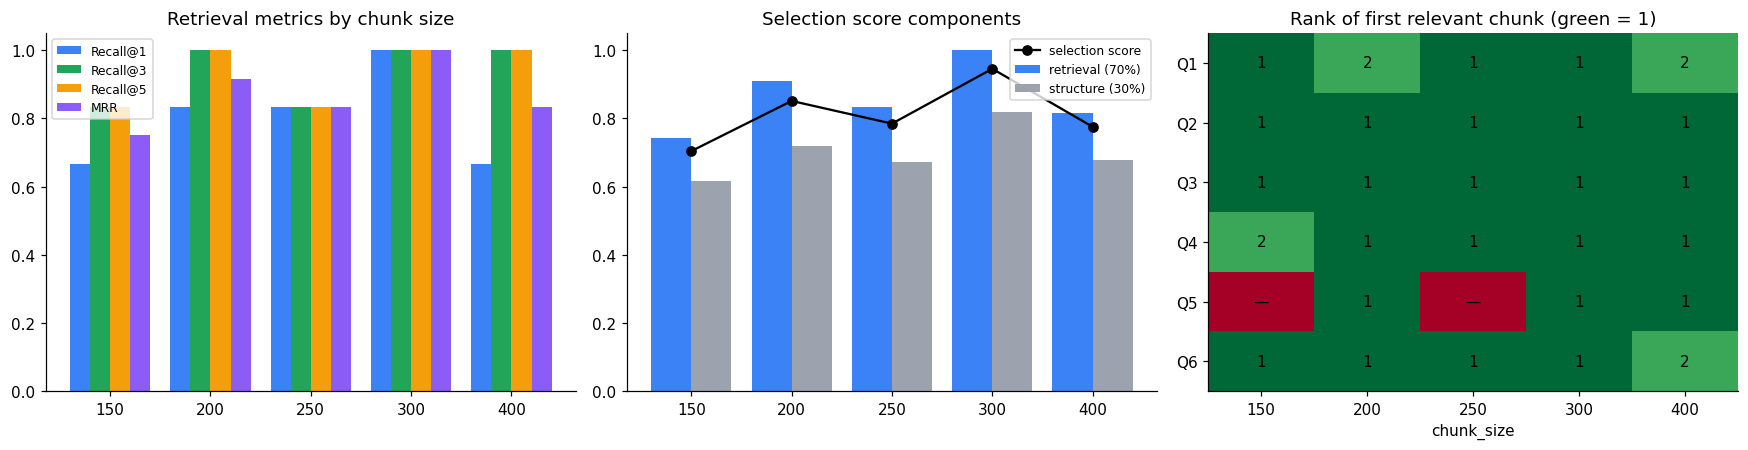

### Result: which chunk size retrieved best?

Using the heuristic defined in §15 (70% retrieval + 30% structure), the highest selection score belongs to **chunk_size = 300** (overlap 45):
selection score **0.945**, MRR **1.000**, Recall@1 **1.00**, 5 chunks.

* Pure retrieval view: highest MRR is **300** (1.000); highest Recall@1 is **300** (1.00).
* Sizes at which some query's evidence was split across chunks (answerable < 100%): **150, 250**.
* Caveat: 6 queries on a single 1210-character document, so differences of one rank position are not statistically meaningful. The *method* is the contribution; re-run with your own documents and queries.


In [37]:
# ── Selection by the transparent heuristic (ties → fewer chunks) ──────────────
summary_df = summary_df.sort_values("chunk_size").reset_index(drop=True)
best_row = summary_df.sort_values(["selection score", "# chunks"], ascending=[False, True]).iloc[0]
BEST_SIZE = int(best_row["chunk_size"]); BEST_OVERLAP = int(best_row["overlap"])

def notes_for(row):
    n = []
    if row["# chunks"] <= EVAL_K: n.append(f"only {int(row['# chunks'])} chunks → Recall@{EVAL_K} is trivially 1")
    if row["answerable"] < 1: n.append(f"{int(round((1-row['answerable'])*len(QUERIES)))} query(ies) cut apart by chunking")
    if row["Recall@1"] == 1: n.append("top-1 always correct")
    return "; ".join(n) or "—"
summary_df["notes"] = summary_df.apply(notes_for, axis=1)

def highlight_best(s): return ["background-color: rgba(34,165,89,.25); font-weight:bold" if s["chunk_size"] == BEST_SIZE else "" for _ in s]
display(summary_df.style.format({"avg len": "{:.1f}", "Recall@1": "{:.2f}", "Recall@3": "{:.2f}", "Recall@5": "{:.2f}", "MRR": "{:.3f}",
        "answerable": "{:.0%}", "avg top-1 chunk len": "{:.0f}", "retrieval score": "{:.3f}", "structure score": "{:.3f}", "selection score": "{:.3f}"})
        .apply(highlight_best, axis=1).hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2)); xs = np.arange(len(summary_df)); w = .2
for j, (m, col) in enumerate([("Recall@1", "#3b82f6"), ("Recall@3", "#22a559"), ("Recall@5", "#f59e0b"), ("MRR", "#8b5cf6")]):
    axes[0].bar(xs + (j - 1.5) * w, summary_df[m], w, label=m, color=col)
axes[0].set_xticks(xs); axes[0].set_xticklabels(summary_df["chunk_size"]); axes[0].set_ylim(0, 1.05); axes[0].set_title("Retrieval metrics by chunk size"); axes[0].legend(fontsize=8)
axes[1].bar(xs - .2, summary_df["retrieval score"], .4, label="retrieval (70%)", color="#3b82f6"); axes[1].bar(xs + .2, summary_df["structure score"], .4, label="structure (30%)", color="#9ca3af")
axes[1].plot(xs, summary_df["selection score"], "ko-", label="selection score"); axes[1].set_xticks(xs); axes[1].set_xticklabels(summary_df["chunk_size"]); axes[1].legend(fontsize=8); axes[1].set_title("Selection score components")
im = axes[2].imshow(rank_matrix.fillna(99).values, cmap="RdYlGn_r", vmin=1, vmax=8, aspect="auto")
axes[2].set_xticks(range(len(CHUNK_SIZES))); axes[2].set_xticklabels(CHUNK_SIZES); axes[2].set_yticks(range(len(QUERIES))); axes[2].set_yticklabels(rank_matrix.index)
for i in range(rank_matrix.shape[0]):
    for j in range(rank_matrix.shape[1]):
        v = rank_matrix.iloc[i, j]; axes[2].text(j, i, "—" if pd.isna(v) else int(v), ha="center", va="center", fontsize=10)
axes[2].set_title("Rank of first relevant chunk (green = 1)"); axes[2].set_xlabel("chunk_size")
plt.tight_layout(); plt.show()

display(Markdown(f"""### Result: which chunk size retrieved best?

Using the heuristic defined in §15 (70% retrieval + 30% structure), the highest selection score belongs to **chunk_size = {BEST_SIZE}** (overlap {BEST_OVERLAP}):
selection score **{best_row['selection score']:.3f}**, MRR **{best_row['MRR']:.3f}**, Recall@1 **{best_row['Recall@1']:.2f}**, {int(best_row['# chunks'])} chunks.

* Pure retrieval view: highest MRR is **{summary_df.loc[summary_df['MRR'].idxmax(), 'chunk_size']}** ({summary_df['MRR'].max():.3f}); highest Recall@1 is **{summary_df.loc[summary_df['Recall@1'].idxmax(), 'chunk_size']}** ({summary_df['Recall@1'].max():.2f}).
* Sizes at which some query's evidence was split across chunks (answerable < 100%): **{', '.join(str(int(r['chunk_size'])) for _, r in summary_df.iterrows() if r['answerable'] < 1) or 'none'}**.
* Caveat: {len(QUERIES)} queries on a single {len(DOCUMENT)}-character document, so differences of one rank position are not statistically meaningful. The *method* is the contribution; re-run with your own documents and queries.
"""))

### Overlap ratio sweep at the selected chunk size

The brief asks us to justify overlap rather than guess it. For the selected chunk size we vary the ratio (0% = baseline, then 10%, 15%, 20%, and 30% to show *too much*) and re-run the **entire** pipeline for each (split → embed → Qdrant → evaluate). The best ratio among 10/15/20% is chosen with the same heuristic; 0% and 30% are shown as reference points.

In [38]:
RATIOS = [0.0, 0.10, 0.15, 0.20, 0.30]
sweep = []
for ratio in RATIOS:
    ov = overlap_for(BEST_SIZE, ratio)
    res, _, summ = evaluate_config(BEST_SIZE, ov, name=f"sweep_{BEST_SIZE}_{ov}")
    st = res.stats()
    sweep.append({"ratio": f"{ratio:.0%}", "overlap budget": ov, "# chunks": st["n_chunks"], "actual overlap chars (total)": st["overlap_chars"],
                  "stored chars (Σ chunk len)": sum(len(c) for c in res.chunks), "duplication vs document": sum(len(c) for c in res.chunks) / len(DOCUMENT) - 1,
                  "Recall@1": summ["Recall@1"], "MRR": summ["MRR"], "answerable": summ["answerable"], "selection score": summ["selection score"], "_r": ratio})
sweep_df = pd.DataFrame(sweep)
cand = sweep_df[sweep_df["_r"].isin([0.10, 0.15, 0.20])].sort_values(["selection score", "overlap budget"], ascending=[False, True])
BEST_RATIO = float(cand.iloc[0]["_r"]); BEST_IDX = int(cand.index[0]); BEST_OVERLAP = overlap_for(BEST_SIZE, BEST_RATIO)
display(sweep_df.drop(columns="_r").style.format({"duplication vs document": "{:+.1%}", "Recall@1": "{:.2f}", "MRR": "{:.3f}", "answerable": "{:.0%}", "selection score": "{:.3f}"})
        .apply(lambda s: ["background-color: rgba(34,165,89,.25); font-weight:bold" if s.name == BEST_IDX else "" for _ in s], axis=1).hide(axis="index"))
print(f"→ Selected configuration: chunk_size = {BEST_SIZE}, overlap_ratio = {BEST_RATIO:.0%}, overlap = {BEST_OVERLAP} characters.")
print("  'actual overlap chars' can be below the budget because overlap is built from whole pieces (see §12).")
print("  'duplication vs document' = extra characters stored because of overlap, i.e. the storage/embedding cost of the safety margin.")

ratio,overlap budget,# chunks,actual overlap chars (total),stored chars (Σ chunk len),duplication vs document,Recall@1,MRR,answerable,selection score
0%,0,5,0,1204,-0.5%,1.00,1.000,100%,0.943
10%,30,5,27,1232,+1.8%,1.00,1.000,100%,0.945
15%,45,5,27,1232,+1.8%,1.00,1.000,100%,0.945
20%,60,6,106,1311,+8.3%,0.83,0.917,100%,0.841
30%,90,6,254,1460,+20.7%,1.00,1.000,100%,0.935


→ Selected configuration: chunk_size = 300, overlap_ratio = 10%, overlap = 30 characters.
  'actual overlap chars' can be below the budget because overlap is built from whole pieces (see §12).
  'duplication vs document' = extra characters stored because of overlap, i.e. the storage/embedding cost of the safety margin.


## 24. Groq RAG Generation

### Why do we give the LLM the retrieved chunks?

A language model only knows what was in its training data plus whatever is in its **prompt**. It has never seen our fictional café's price list. If we ask "How much is green tea?" with no context it can only guess or invent. **Retrieval-Augmented Generation** puts the few relevant chunks into the prompt so the model can *read* the answer instead of *remembering* it. We also instruct it to answer **only from the context** and to say when the context is insufficient, which reduces (but does not eliminate) invented answers.

```text
SYSTEM INSTRUCTIONS   ("answer only from the context, cite chunk ids, say 'I don't know' if absent")
        +
RETRIEVED CONTEXT     (top-k chunks with their similarity scores)
        +
USER QUESTION
        ↓
      GROQ  (hosted LLM; the API key comes from the GROQ_API_KEY environment variable)
        ↓
FINAL ANSWER
```

The API key is never written in the notebook and never printed. If it is missing, the generation step is skipped with an explanation and everything before it still works.

In [39]:
SYSTEM_PROMPT = ("You are a careful assistant that answers questions about a café's information page.\n"
                 "Use ONLY the information in the CONTEXT. If the context does not contain the answer, reply exactly: "
                 "\"I don't know based on the provided context.\"\n"
                 "Keep the answer short and mention the chunk id(s) you used, like [Chunk 3].")

def format_context(hits):
    """hits: list of dicts {chunk_id, score, text, start, end}"""
    blocks = [f"[Chunk {h['chunk_id']} | similarity={h['score']:.2f} | chars {h['start']}–{h['end']}]\n{h['text']}" for h in hits]
    return "\n\n".join(blocks)

def display_retrieved_context(hits):
    ctx = format_context(hits)
    bar = "=" * 18
    print(f"{bar} RETRIEVED CONTEXT {bar}\n\n{ctx}\n\n{'=' * 55}")
    return ctx

def build_messages(question, context):
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"CONTEXT:\n{context}\n\nQUESTION: {question}"}]

def call_groq(messages, model=GROQ_MODEL, temperature=0.0, max_tokens=300):
    """Returns (answer, error_message). Never raises; never prints the API key."""
    key = get_groq_key()
    if not key:
        return None, "GROQ_API_KEY not found. Generation skipped (chunking → embeddings → Qdrant → retrieval still ran)."
    try:
        try:
            from groq import Groq
            r = Groq(api_key=key).chat.completions.create(model=model, messages=messages, temperature=temperature, max_tokens=max_tokens)
            return r.choices[0].message.content, None
        except ImportError:                                        # SDK not installed → plain HTTPS
            import requests
            resp = requests.post("https://api.groq.com/openai/v1/chat/completions", timeout=60,
                                 headers={"Authorization": f"Bearer {key}", "Content-Type": "application/json"},
                                 json={"model": model, "messages": messages, "temperature": temperature, "max_tokens": max_tokens})
            resp.raise_for_status()
            return resp.json()["choices"][0]["message"]["content"], None
    except Exception as e:
        return None, f"Groq request failed ({type(e).__name__}): {str(e)[:300]}\nCheck the key, the model name GROQ_MODEL='{model}', your network and Groq's rate limits."

print("System prompt that will be sent:\n" + "-" * 60 + "\n" + SYSTEM_PROMPT)

System prompt that will be sent:
------------------------------------------------------------
You are a careful assistant that answers questions about a café's information page.
Use ONLY the information in the CONTEXT. If the context does not contain the answer, reply exactly: "I don't know based on the provided context."
Keep the answer short and mention the chunk id(s) you used, like [Chunk 3].


## 25. Complete End-to-End Pipeline

We now run **one complete example** with the configuration selected by experiment (§23), printing every intermediate result so that the final answer can be traced back to the original characters:

```text
1210-character document → best chunk size → recursive chunking → final chunks → MiniLM embeddings → Qdrant
→ user question → query embedding → similarity search → top-k chunks → retrieved context → Groq → final answer
```

The question below needs **reasoning over a retrieved fact** ("is cash accepted at 17:00?"), not a simple lookup.

In [40]:
def rag_pipeline(question, chunk_size, overlap, top_k=TOP_K, generate=True, evidence=None):
    def stage(n, title): print("\n" + "█" * 4 + f" STAGE {n}: {title} " + "█" * 4)
    out = {}
    stage(1, "RAW DOCUMENT"); print(f"{len(DOCUMENT)} characters, {len(DOCUMENT.split(chr(10)+chr(10)))} paragraphs")
    stage(2, f"RECURSIVE CHUNKING (chunk_size={chunk_size}, overlap={overlap})")
    res = TracingRecursiveSplitter(chunk_size, overlap).split(DOCUMENT); st = res.stats()
    print(f"{st['n_chunks']} chunks · {st['n_calls']} recursive calls · max depth {st['max_depth']} · {st['n_merge_ops']} merge decisions"); display_chunk_table(res, 60)
    stage(3, "EMBEDDING (local MiniLM)"); vecs = embed_texts([c.text for c in res.chunks]); print(f"{vecs.shape[0]} vectors × {vecs.shape[1]} dims, dtype {vecs.dtype}")
    stage(4, "QDRANT COLLECTION"); name = f"final_{chunk_size}_{overlap}"; build_collection(name, res, vecs)
    print(f"collection '{name}': {qdrant.count(collection_name=name, exact=True).count} points, vector size {EMB_DIM}, cosine distance")
    stage(5, "USER QUERY → QUERY EMBEDDING"); print("QUESTION:", question); qv = show_query_embedding(question)
    stage(6, "SIMILARITY SEARCH"); order, scores = manual_rank(qv, vecs)
    qhits = qdrant_search(name, qv, top_k)
    print("Manual NumPy ranking (top-%d): %s" % (top_k, [(int(i), round(float(scores[i]), 4)) for i in order[:top_k]]))
    print("Qdrant ranking       (top-%d): %s" % (top_k, [(h.id, round(h.score, 4)) for h in qhits]))
    hits = [{"chunk_id": h.id, "score": h.score, "text": h.payload["text"], "start": h.payload["start_char"], "end": h.payload["end_char"]} for h in qhits]
    stage(7, "RETRIEVED CONTEXT (exactly what the LLM will see)"); ctx = display_retrieved_context(hits)
    if evidence is not None:
        ok = any(all(e in h["text"] for e in evidence) for h in hits)
        print(f"\nCheck: does at least one retrieved chunk contain ALL the evidence {evidence}?  →  {'YES ✔' if ok else 'NO ✘ (retrieval missed or split the evidence)'}")
        out["evidence_in_context"] = ok
    msgs = build_messages(question, ctx)
    stage(8, "FINAL PROMPT SENT TO GROQ (API key is never part of it)")
    for m in msgs: print(f"--- role: {m['role']} ---\n{m['content']}\n")
    answer = err = None
    if generate:
        stage(9, f"GROQ GENERATION (model {GROQ_MODEL})"); answer, err = call_groq(msgs)
        print("FINAL ANSWER:\n  " + answer.replace("\n", "\n  ") if answer else "⚠ " + err)
    out.update(result=res, vectors=vecs, hits=hits, context=ctx, messages=msgs, answer=answer, error=err, question=question, qvec=qv)
    return out

E2E_QUESTION = "I want to pay in cash on a weekday at 17:00. Is that allowed?"
E2E_EVIDENCE = ["Cash is not accepted after 16:00"]
e2e = rag_pipeline(E2E_QUESTION, BEST_SIZE, BEST_OVERLAP, evidence=E2E_EVIDENCE)


████ STAGE 1: RAW DOCUMENT ████
1210 characters, 2 paragraphs

████ STAGE 2: RECURSIVE CHUNKING (chunk_size=300, overlap=30) ████
5 chunks · 3 recursive calls · max depth 1 · 22 merge decisions


Chunk,start,end,length,overlap w/ prev,from call,depth,pieces merged,preview
0,0,279,279,0,#2,1,6,"""## Maple Hall Student Café & S … 75\n- Lentil Soup ........ 3.25"""
1,252,525,273,27,#2,1,8,"""- Lentil Soup ........ 3.25\n| … al [ ] Gluten-free [ ] Vegan"""
2,526,740,214,0,#2,1,3,"""Opening hours: Mon-Fri 08:00-1 … iry or sesame before ordering."""
3,742,1035,293,0,#3,1,3,"""Many universities now treat th … e cup schemes also lower waste"""
4,1037,1210,173,0,#3,1,3,"""Staff often report that regula … . Quiet corners help revision."""



████ STAGE 3: EMBEDDING (local MiniLM) ████
5 vectors × 384 dims, dtype float32

████ STAGE 4: QDRANT COLLECTION ████
collection 'final_300_30': 5 points, vector size 384, cosine distance

████ STAGE 5: USER QUERY → QUERY EMBEDDING ████
QUESTION: I want to pay in cash on a weekday at 17:00. Is that allowed?
USER QUERY
    I want to pay in cash on a weekday at 17:00. Is that allowed?
      ↓  (embedding model: sentence-transformers/all-MiniLM-L6-v2)
QUERY EMBEDDING
    shape=(384,) dtype=float32 norm=1.000   first values: [-0.012  0.05  -0.019 -0.042  0.    -0.057] …
      ↓
VECTOR DIMENSION
    384 (must equal the Qdrant collection's vector size: 384 )

████ STAGE 6: SIMILARITY SEARCH ████
Manual NumPy ranking (top-3): [(2, 0.3672), (0, 0.1563), (4, 0.1145)]
Qdrant ranking       (top-3): [(2, 0.3672), (0, 0.1563), (4, 0.1145)]

████ STAGE 7: RETRIEVED CONTEXT (exactly what the LLM will see) ████
================== RETRIEVED CONTEXT ==================

[Chunk 2 | similarity=0.37 | char

### Trace the answer back to the document

Every retrieved chunk carries its provenance. Below, the **top-ranked chunk** is followed back through merge → pieces → recursive calls → original characters (the same `trace_chunk` tool from §11), and the whole path is drawn: question vector and chunk vectors in embedding space, and the pipeline with the real numbers from this run.

Top retrieved chunk = 2 (similarity 0.367), document characters 526–740

══════════════════════════════════════════════════════════════════════════════
WHERE DID CHUNK 2 COME FROM?
══════════════════════════════════════════════════════════════════════════════
FINAL CHUNK 2: 214 chars, document span [526:740], exact slice of the original: True
    "Opening hours: Mon-Fri 08:00-18:00; Sat 09:00-14:00; closed Sunday.\nPolicy: Reusable cups receive
    a  …  Cash is not accepted after 16:00.\nAllergens: ask staff about nuts, dairy or sesame before
    ordering."

   ↑ produced by MERGE GROUP 1 inside call #2. Pieces merged: ['#2.P13', '#2.P14', '#2.P15']
       merge step: piece #2.P13 → REJECT (341 vs 300): this piece opened this chunk (it overflowed the previous chunk, which was closed)
       merge step: piece #2.P14 → ACCEPT (148 vs 300): ACCEPT: the piece joined this chunk
       merge step: piece #2.P15 → ACCEPT (214 vs 300): ACCEPT: the piece joined this chunk

   ↑ the pieces came 

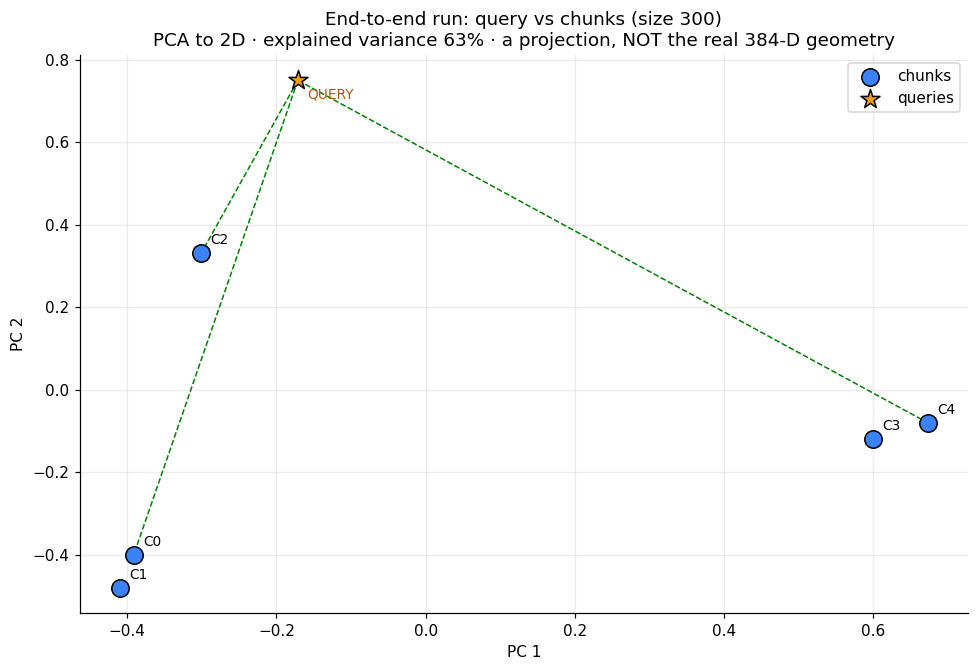

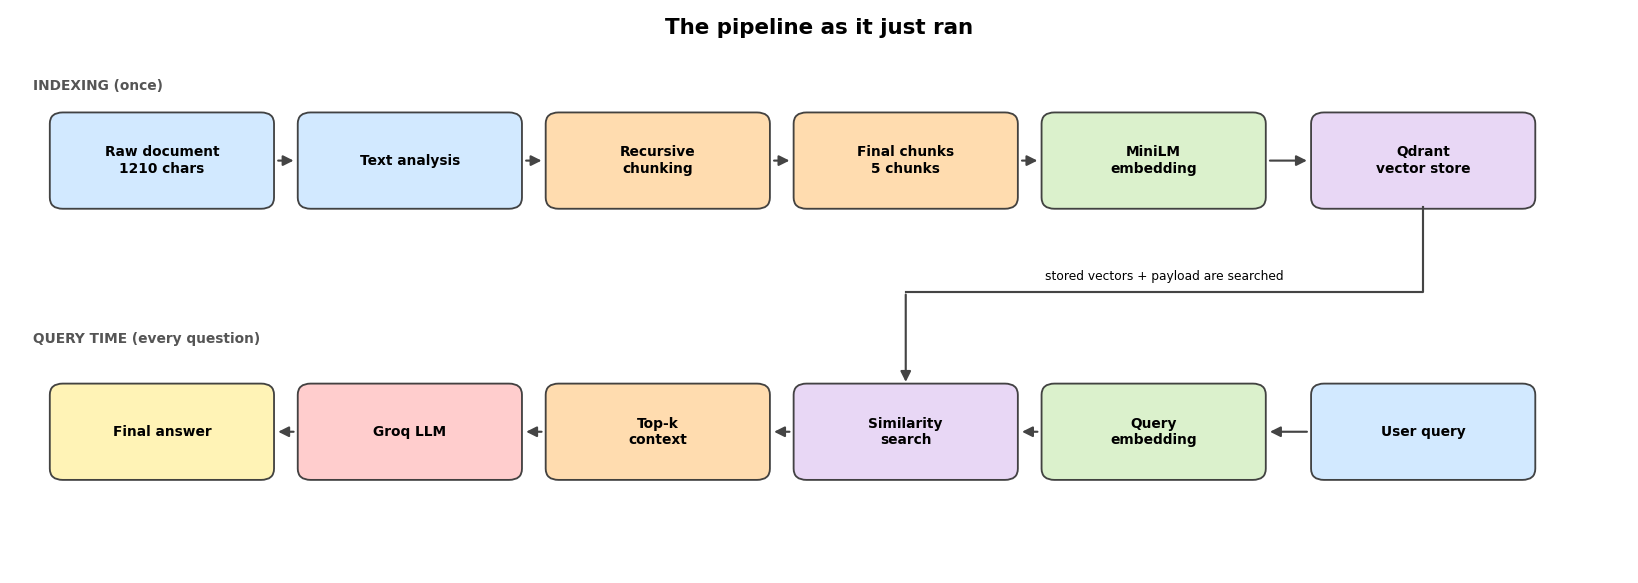

In [41]:
top = e2e["hits"][0]
print(f"Top retrieved chunk = {top['chunk_id']} (similarity {top['score']:.3f}), document characters {top['start']}–{top['end']}\n")
trace_chunk(e2e["result"], top["chunk_id"])

res = e2e["result"]
plot_embedding_projection(e2e["vectors"], [f"C{c.chunk_id}" for c in res.chunks], e2e["qvec"][None, :], ["QUERY"],
                          f"End-to-end run: query vs chunks (size {res.chunk_size})", highlight=[(0, h["chunk_id"]) for h in e2e["hits"]])
draw_pipeline("The pipeline as it just ran", numbers={"doc": f"{len(DOCUMENT)} chars", "chunks": f"{len(res.chunks)} chunks"})

## 26. LangChain Comparison

Our splitter is an **educational reimplementation**. To be sure it is faithful, we run LangChain's production `RecursiveCharacterTextSplitter` with equivalent settings (same separators, `is_separator_regex=False`, same size and overlap) and compare chunk texts one by one. LangChain's `keep_separator` option decides whether the separator is thrown away (`False`), glued to the start of the following piece (`"start"`, same as `True`) or to the end of the previous one (`"end"`). We test all three, for all five chunk sizes. We also run LangChain with **its own defaults** to show how a library default can differ from our (explicitly chosen) `keep_separator=False`.

In [42]:
try:
    from langchain_text_splitters import RecursiveCharacterTextSplitter
    LC_AVAILABLE = True
except Exception as e:
    LC_AVAILABLE = False; print("langchain-text-splitters unavailable:", e)

lc_rows, first_diff = [], None
if LC_AVAILABLE:
    print("langchain-text-splitters", pkg_version("langchain-text-splitters"))
    for cs in CHUNK_SIZES:
        ov = overlap_for(cs)
        for ks in (False, "start", "end"):
            mine = TracingRecursiveSplitter(cs, ov, keep_separator=ks).split(DOCUMENT)
            try:
                splitter = RecursiveCharacterTextSplitter(chunk_size=cs, chunk_overlap=ov, separators=SEPARATORS, keep_separator=ks,
                                                         is_separator_regex=False, add_start_index=True)
                docs = splitter.create_documents([DOCUMENT])
            except Exception as e:
                lc_rows.append({"chunk_size": cs, "keep_separator": ks, "result": f"LangChain error: {type(e).__name__}: {str(e)[:60]}"}); continue
            lc_text = [d.page_content for d in docs]; my_text = [c.text for c in mine.chunks]
            lc_start = [d.metadata.get("start_index") for d in docs]
            same_text = lc_text == my_text
            same_start = lc_start == [c.start for c in mine.chunks]
            if not same_text and first_diff is None:
                first_diff = (cs, ks, lc_text, my_text)
            lc_rows.append({"chunk_size": cs, "keep_separator": str(ks), "# chunks (ours)": len(my_text), "# chunks (LangChain)": len(lc_text),
                            "identical chunk texts": "✔" if same_text else "✘", "identical start offsets": "✔" if same_start else "✘ (LangChain finds offsets by text search)",
                            "ours: overlap chars": sum(c.overlap_prev for c in mine.chunks)})
    lc_df = pd.DataFrame(lc_rows); display(lc_df.style.hide(axis="index"))

    # LangChain with its OWN defaults (keep_separator=True → "start"): what changes?
    cs = DEMO_CHUNK_SIZE; ov = overlap_for(cs)
    lib_default = RecursiveCharacterTextSplitter(chunk_size=cs, chunk_overlap=ov, separators=SEPARATORS).split_text(DOCUMENT)
    ours_default = [c.text for c in TracingRecursiveSplitter(cs, ov).split(DOCUMENT).chunks]
    print(f"\nLangChain with default options at chunk_size={cs}: {len(lib_default)} chunks; ours (keep_separator=False): {len(ours_default)} chunks; identical: {lib_default == ours_default}")
    for i, (a, b) in enumerate(zip(lib_default, ours_default)):
        if a != b: print(f"  first difference at chunk {i}:\n    LangChain: {q(a, 90)}\n    ours     : {q(b, 90)}"); break
    if first_diff:
        cs_, ks_, a, b = first_diff; print(f"\nFirst mismatch (chunk_size={cs_}, keep_separator={ks_}): {len(a)} vs {len(b)} chunks")
        for i, (x, y) in enumerate(zip(a, b)):
            if x != y: print(f"  chunk {i}\n    LangChain: {q(x, 100)}\n    ours     : {q(y, 100)}"); break

langchain-text-splitters 1.1.3


chunk_size,keep_separator,# chunks (ours),# chunks (LangChain),identical chunk texts,identical start offsets,ours: overlap chars
150,False,12,12,✔,✔,18
150,start,12,12,✔,✔,18
150,end,12,12,✔,✔,18
200,False,8,8,✔,✔,4
200,start,8,8,✔,✔,4
200,end,8,8,✔,✔,4
250,False,7,7,✔,✔,66
250,start,7,7,✔,✔,66
250,end,7,7,✔,✔,66
300,False,5,5,✔,✔,27



LangChain with default options at chunk_size=150: 12 chunks; ours (keep_separator=False): 12 chunks; identical: False
  first difference at chunk 8:
    LangChain: ". Students gather there between lectures to r …  group meetings and decide what to study next"
    ours     : "Students gather there between lectures to rev …  group meetings and decide what to study next"


In [43]:
if LC_AVAILABLE and lc_rows:
    n_ok = sum(r.get("identical chunk texts") == "✔" for r in lc_rows); n_all = len(lc_rows)
    display(Markdown(f"""### What the comparison shows

**Chunk-text equality: {n_ok} of {n_all} configurations are identical** between our implementation and LangChain `{pkg_version('langchain-text-splitters')}`.
{"Because our splitter reproduces the same decisions (same fit rule, same merge/overlap bookkeeping), differences are not expected here." if n_ok == n_all else "Where they differ, the first mismatch is printed above; inspect it before trusting either implementation blindly."}

### Why might an implementation differ slightly from LangChain?

* **Library version.** The merge/overlap code and the handling of `keep_separator` have changed across releases. This comparison is valid for the installed version only.
* **`keep_separator` default.** LangChain's default keeps separators (attached to the start of the next piece); ours defaults to `False` (separators discarded, re-inserted when merging) because it is easier to read. Switching modes changes chunk text, not the algorithm.
* **Regex vs literal.** LangChain compiles separators into regular expressions (escaped unless `is_separator_regex=True`). A literal-string implementation behaves the same for plain separators, but would differ for regex separators.
* **Fit rule and strip.** A piece is "small enough" only if `len < chunk_size` (strict), and chunks are `strip()`-ped, so whitespace-only chunks vanish. An implementation using `≤` or not stripping will produce different boundaries.
* **Start offsets.** Ours are tracked exactly while splitting. LangChain's `add_start_index` locates each chunk afterwards with a text search, which can drift if a chunk's text occurs earlier in the document.
* **Length function.** Both measure characters here. LangChain can also count tokens (`from_tiktoken_encoder`); chunk boundaries then differ.

**Conceptual algorithm vs our implementation vs LangChain:** the *concept* (split on the coarsest separator, recurse on oversized pieces with finer ones, merge, overlap) is shared. Our code is a transparent, instrumented implementation of that concept, and LangChain's is an optimised library implementation of it. They agree here, but we only claim equality for the tested settings.
"""))

### What the comparison shows

**Chunk-text equality: 15 of 15 configurations are identical** between our implementation and LangChain `1.1.3`.
Because our splitter reproduces the same decisions (same fit rule, same merge/overlap bookkeeping), differences are not expected here.

### Why might an implementation differ slightly from LangChain?

* **Library version.** The merge/overlap code and the handling of `keep_separator` have changed across releases. This comparison is valid for the installed version only.
* **`keep_separator` default.** LangChain's default keeps separators (attached to the start of the next piece); ours defaults to `False` (separators discarded, re-inserted when merging) because it is easier to read. Switching modes changes chunk text, not the algorithm.
* **Regex vs literal.** LangChain compiles separators into regular expressions (escaped unless `is_separator_regex=True`). A literal-string implementation behaves the same for plain separators, but would differ for regex separators.
* **Fit rule and strip.** A piece is "small enough" only if `len < chunk_size` (strict), and chunks are `strip()`-ped, so whitespace-only chunks vanish. An implementation using `≤` or not stripping will produce different boundaries.
* **Start offsets.** Ours are tracked exactly while splitting. LangChain's `add_start_index` locates each chunk afterwards with a text search, which can drift if a chunk's text occurs earlier in the document.
* **Length function.** Both measure characters here. LangChain can also count tokens (`from_tiktoken_encoder`); chunk boundaries then differ.

**Conceptual algorithm vs our implementation vs LangChain:** the *concept* (split on the coarsest separator, recurse on oversized pieces with finer ones, merge, overlap) is shared. Our code is a transparent, instrumented implementation of that concept, and LangChain's is an optimised library implementation of it. They agree here, but we only claim equality for the tested settings.


## 27. Final Results

All numbers below come from the experiments executed above in this notebook. Nothing is typed in by hand.

In [44]:
final_df = summary_df[["chunk_size", "overlap", "# chunks", "avg len", "max depth", "Recall@1", "Recall@3", "MRR", "answerable", "selection score", "notes"]].copy()
final_df = final_df.merge(struct_df[["chunk_size", "n_calls", "n_merge_ops"]], on="chunk_size").rename(columns={"n_calls": "# calls", "n_merge_ops": "# merge ops"})
final_df["verdict"] = np.where(final_df["chunk_size"] == BEST_SIZE, "★ selected", "")
display(final_df.style.format({"avg len": "{:.1f}", "Recall@1": "{:.2f}", "Recall@3": "{:.2f}", "MRR": "{:.3f}", "answerable": "{:.0%}", "selection score": "{:.3f}"})
        .apply(highlight_best, axis=1).hide(axis="index"))
print(f"Embedding backend: {embedder.name}" + ("   ⚠ STAND-IN: these retrieval numbers are NOT MiniLM results" if embedder.is_fallback else ""))
print(f"Selected: chunk_size={BEST_SIZE}, overlap={BEST_OVERLAP} ({BEST_RATIO:.0%}).   Generation model: {GROQ_MODEL}")

chunk_size,overlap,# chunks,avg len,max depth,Recall@1,Recall@3,MRR,answerable,selection score,notes,# calls,# merge ops,verdict
150,22,12,101.1,2,0.67,0.83,0.750,83%,0.704,1 query(ies) cut apart by chunking,4,45,
200,30,8,150.6,1,0.83,1.00,0.917,100%,0.851,—,3,22,
250,38,7,181.3,1,0.83,0.83,0.833,83%,0.785,1 query(ies) cut apart by chunking,3,22,
300,45,5,246.4,1,1.00,1.00,1.000,100%,0.945,only 5 chunks → Recall@5 is trivially 1; top-1 always correct,3,22,★ selected
400,60,4,310.0,1,0.67,1.00,0.833,100%,0.775,only 4 chunks → Recall@5 is trivially 1,3,22,


Embedding backend: sentence-transformers/all-MiniLM-L6-v2
Selected: chunk_size=300, overlap=30 (10%).   Generation model: llama-3.3-70b-versatile


## 28. What We Learned

### Computed from this notebook's own experiments

In [45]:
small, large = min(CHUNK_SIZES), max(CHUNK_SIZES)
c_small, c_large = EXPERIMENT[small].stats(), EXPERIMENT[large].stats()
cut = [cs for cs in CHUNK_SIZES if integrity[cs].eq(0).any()]
display(Markdown(f"""* **Smaller chunk size → more chunks and more recursion.** `chunk_size={small}` produced {c_small['n_chunks']} chunks with {c_small['n_calls']} recursive calls (max depth {c_small['max_depth']}); `chunk_size={large}` produced {c_large['n_chunks']} chunks with {c_large['n_calls']} calls (max depth {c_large['max_depth']}).
* **Chunking can destroy evidence before retrieval starts.** Chunk sizes where some query's evidence was split across chunks: **{', '.join(map(str, cut)) or 'none'}**. At those sizes no retriever can answer that query from a single chunk.
* **The selected size was chosen by experiment, not by taste:** chunk_size **{BEST_SIZE}** had the highest combined score ({best_row['selection score']:.3f}); its Recall@1 was {best_row['Recall@1']:.2f} and MRR {best_row['MRR']:.3f}.
* **Overlap has a price.** In the sweep at chunk_size {BEST_SIZE}, going from 0% to 30% overlap changed stored characters from {sweep_df.iloc[0]['stored chars (Σ chunk len)']} to {sweep_df.iloc[-1]['stored chars (Σ chunk len)']} ({sweep_df.iloc[-1]['duplication vs document']:+.0%} versus the document), and the selected ratio was **{BEST_RATIO:.0%}**.
* **Recall@k flatters coarse chunking.** Sizes with ≤ {EVAL_K} chunks get Recall@{EVAL_K} = 1 automatically, which is why MRR and Recall@1 weigh more in our score.
"""))

* **Smaller chunk size → more chunks and more recursion.** `chunk_size=150` produced 12 chunks with 4 recursive calls (max depth 2); `chunk_size=400` produced 4 chunks with 3 calls (max depth 1).
* **Chunking can destroy evidence before retrieval starts.** Chunk sizes where some query's evidence was split across chunks: **150, 250**. At those sizes no retriever can answer that query from a single chunk.
* **The selected size was chosen by experiment, not by taste:** chunk_size **300** had the highest combined score (0.945); its Recall@1 was 1.00 and MRR 1.000.
* **Overlap has a price.** In the sweep at chunk_size 300, going from 0% to 30% overlap changed stored characters from 1204 to 1460 (+21% versus the document), and the selected ratio was **10%**.
* **Recall@k flatters coarse chunking.** Sizes with ≤ 5 chunks get Recall@5 = 1 automatically, which is why MRR and Recall@1 weigh more in our score.


### Conceptual lessons (these do not depend on a particular run)

**Why smaller chunks can help.** One vector summarises one chunk. A short chunk about *one* thing (a single table row, a single policy line) yields a vector dominated by that thing, so a question about it matches strongly. Smaller chunks also put less irrelevant text into the prompt.

**Why larger chunks can help.** A larger chunk keeps related facts together and gives the LLM surrounding context. It also lowers the risk that a fact is cut in half, and it means fewer vectors to store and search.

**Why overlap exists.** It repeats the end of one chunk at the start of the next so that a fact lying across a boundary has a chance to appear whole in at least one chunk.

**Why too much overlap wastes resources.** More duplicated text means more characters to embed and store, near-duplicate chunks that compete for top-k slots, and repeated text in the prompt. (See the sweep table.)

**Why tables, menus and checkboxes complicate naive chunking.** Their meaning lives in *layout*: a price belongs to the item on the same row; `[x]`/`[ ]` is meaningful only next to its label. A splitter that counts characters can cut between a label and its value, and a vector model sees such text as noisy symbols. Splitting on `"\n"` before spaces keeps rows intact, which is exactly what the separator hierarchy buys us.

**Why separators matter.** They decide *where cuts are allowed*. A good hierarchy cuts at the most meaningful boundary that still satisfies the size limit and only falls back to cruder boundaries when forced.

**Why semantic boundaries beat arbitrary character boundaries.** A chunk that starts and ends at a paragraph, line or sentence boundary usually contains complete thoughts, which embed more coherently than a chunk that starts mid-word.

**Why recursive chunking is a heuristic, not magic.** It encodes a *guess*: "text with blank lines, newlines and full stops is probably organised so that these marks separate ideas". The guess is often right and cheap, but it can fail, and nothing in the algorithm checks it.

## 29. Limitations & What Recursive Chunking Does *Not* Do

### What recursive character splitting does not understand

It does **not** inherently understand:

* **meaning**: it never reads the words, it only looks for separator strings and counts characters;
* **topic**: a chunk boundary does not mean a topic change; two lines about different subjects can be merged just because together they are shorter than `chunk_size`;
* **semantic similarity**: it never compares sentences by meaning (that is the embedding model's job, later);
* **"this table belongs to this heading"**: a heading and its table are separate lines; the heading can end up in a different chunk than the table (look at the chunk table in §8: the heading `## Maple Hall Student Café & Services` is not guaranteed to travel with the menu);
* **whether two sentences answer the same question**: this is why evidence for a question can be split in two chunks.

It relies on **structural separators and size constraints**, and nothing else.

### Limitations of this laboratory

* One small, synthetic document and **six** queries: the metrics illustrate a method; they are not a benchmark. Different documents (long reports, code) can behave very differently.
* Chunk size is measured in **characters**, whereas embedding models and LLMs count **tokens**. MiniLM truncates input at its maximum sequence length (printed in §16).
* Relevance is defined by evidence strings and a strict "all evidence in one chunk" rule; real relevance is fuzzier.
* MiniLM-L6 is small and English-centric; stronger embedding models rank differently.
* The 70/30 weighting in the selection score is a **judgement call**; change it and the winner may change (the constants are in §15).
* The LLM step depends on a hosted API and on prompt wording; LLM answers are not deterministic across providers or versions.
* Qdrant here runs in memory with a handful of vectors; its approximate-search machinery is not stress-tested.

## 30. Final Summary: The Mental Model

```text
Recursive Chunking
==================

1. Start with a large piece of text.
2. Try the highest-level separator.
3. Split the text.
4. Check piece sizes.
5. Keep pieces that fit.
6. Recursively process pieces that are too large.
7. Move to finer separators when necessary.
8. Merge small pieces into final chunks.
9. Apply overlap.
10. Store final chunks.
```

```text
RAG
===

Document
   ↓
Chunks
   ↓
Embeddings
   ↓
Vector Database
   ↓
Query
   ↓
Query Embedding
   ↓
Similarity Search
   ↓
Relevant Chunks
   ↓
LLM
   ↓
Answer
```

**Tracing in both directions**

```text
Final chunk ← merge operation ← split piece ← recursive call ← parent call ← separator decision ← original document
Final answer ← Groq prompt ← retrieved context ← top-k results ← similarity scores ← query embedding ← MiniLM ← user query
```

### Self-check: the project's requirements, verified by code

The cell below inspects the objects created in this notebook (not the text of the notebook) and reports ✔ / ✘.

In [46]:
def no_key_in_file(path="recursive_chunking_rag_lab.ipynb"):
    try: return re.search(r"gsk_[A-Za-z0-9]{20,}", open(path, encoding="utf-8").read()) is None
    except OSError: return True          # file not found next to the kernel: nothing to scan

def check(label, cond, detail=""): return {"": "✔" if cond else "✘", "Requirement": label, "Detail": detail}
demo_calls = demo.calls.values()
fields = {"id", "parent", "depth", "text", "input_len", "separator", "level", "separators_available", "next_separator", "pieces", "chunk_ids"}
ev_types = {e["type"] for e in demo.events}
paths = e2e["result"]
checks = [
    check("Document has exactly 2 paragraphs", len(DOCUMENT.split("\n\n")) == 2),
    check(f"Document has exactly {TARGET_LENGTH} characters", len(DOCUMENT) == TARGET_LENGTH, f"{len(DOCUMENT)}"),
    check("Paragraph 1: sub-heading, table, menu, checkboxes", all(list(structure_checks.values())[:5])),
    check("Paragraph 2 is plain prose", structure_checks["Paragraph 2 is plain prose"]),
    check("Custom recursive splitter implemented; every chunk is an exact slice of the document", all(c.exact_slice for r in EXPERIMENT.values() for c in r.chunks)),
    check("Each recursive call logs id/parent/depth/separator/pieces/next separator", all(fields <= set(c) for c in demo_calls)),
    check("Parent-child relationships recorded", all((c["parent"] is None) == (c["id"] == 1) for c in demo_calls) and any(c["children"] for c in demo_calls)),
    check("Keep/recurse decisions with reasons logged", all(r["action"] and r["reason"] for c in demo_calls for r in c["pieces"])),
    check("Separator transitions logged", "RECURSE" in ev_types, f"{demo.stats()['n_transitions']} transitions"),
    check("Merge operations logged", len(demo.merge_steps) > 0 and "MERGE_STEP" in ev_types, f"{len(demo.merge_steps)} merge steps"),
    check("Recursion tree generated from the trace", "CALL #1" in render_tree_text(demo)),
    check("4–5 chunk sizes evaluated", 4 <= len(CHUNK_SIZES) <= 5, str(CHUNK_SIZES)),
    check("Overlap derived from chunk size (differs per size)", len({overlap_for(cs) for cs in CHUNK_SIZES}) == len(CHUNK_SIZES)),
    check("Retrieval metrics computed (Recall@1/3/5, MRR)", {"Recall@1", "Recall@3", "Recall@5", "MRR"} <= set(summary_df.columns)),
    check("Embedding model loaded locally (MiniLM)", (not embedder.is_fallback) and EMB_DIM == 384, embedder.name),
    check("Qdrant collection holds one point per chunk", qdrant.count(collection_name=WALK_COLLECTION, exact=True).count == len(walk.chunks)),
    check("Qdrant payload has provenance metadata", {"chunk_id", "text", "source", "paragraph", "recursion_depth", "start_char", "end_char", "chunk_size"} <= set(points[0].payload)),
    check("Manual cosine agrees with Qdrant", max_diff < 1e-4, f"max diff {max_diff:.1e}"),
    check("Retrieved context shown before generation", bool(e2e["context"])),
    check("No API key hard-coded in the notebook file", no_key_in_file(), "scans the .ipynb for 'gsk_…' key patterns"),
    check("Groq answer produced (needs GROQ_API_KEY)", e2e["answer"] is not None, "skipped gracefully if no key" if e2e["answer"] is None else GROQ_MODEL),
    check("LangChain comparison executed", LC_AVAILABLE and len(lc_rows) > 0),
]
display(pd.DataFrame(checks).style.hide(axis="index"))
failed = [c["Requirement"] for c in checks if c[""] == "✘"]
print("All checks passed." if not failed else "Not passed (see reasons above; items depending on MiniLM/Groq need network access/API key):\n  - " + "\n  - ".join(failed))

,Requirement,Detail
✔,Document has exactly 2 paragraphs,
✔,Document has exactly 1210 characters,1210
✔,"Paragraph 1: sub-heading, table, menu, checkboxes",
✔,Paragraph 2 is plain prose,
✔,Custom recursive splitter implemented; every chunk is an exact slice of the document,
✔,Each recursive call logs id/parent/depth/separator/pieces/next separator,
✔,Parent-child relationships recorded,
✔,Keep/recurse decisions with reasons logged,
✔,Separator transitions logged,3 transitions
✔,Merge operations logged,45 merge steps


Not passed (see reasons above; items depending on MiniLM/Groq need network access/API key):
  - Groq answer produced (needs GROQ_API_KEY)
